# Réseau électrique — le modèle SP mixte donne-t-il la bonne dynamique ?

**La question.** Le modèle de croissance de réseau de transport de
[`TransmissionGrowthModel`](https://github.com/emileemery) (Emery, Bercegol & Aumaître,
*A Power Grid Growth Model Based on Rural-Urban Differentiation*) suppose une géographie
urbaine **posée à la main** : 11 centres-villes tirés au hasard, autour desquels les postes
se répartissent avec une décroissance exponentielle, plus un fond rural uniforme. Ce repo
dispose d'un modèle spatial **calibré sur les données**, le SP mixte (fractal de
Soneira-Peebles + fond aléatoire, notebooks 01-04). On remplace donc **uniquement la partie
spatiale** :

| | Modèle du papier (`ORI`) | Ce notebook (`SP`) |
|---|---|---|
| nœuds **urbains** | décroissance exponentielle autour de 11 centres | **points du fractal SP** (`is_sp = True`) |
| nœuds **ruraux** | uniformes dans le territoire | **identique** — le fond aléatoire du mélange |
| fraction urbaine | paramètre libre `urban_rate = 0.2` | **émergente**, fixée par la calibration 2PCF |
| connectivité | plus proche voisin (rural) / attachement préférentiel local (urbain), 2ᵉ arête avec proba q | **identique** |
| métadonnée → charge | consommation départementale répartie à parts égales | **attribution (c)** : split SP/fond, aléatoire dans chaque groupe |

et on regarde si les **pertes Joule** tombent au bon endroit.

**Pourquoi les pertes Joule.** C'est la seule observable du papier qui soit à la fois
(i) physique — un watt perdu est un watt perdu — et (ii) publiée : RTE annonce **3,38 %**
de la production. Les observables topologiques (degré, longueur totale) sont beaucoup plus
faciles à reproduire ; les pertes mettent en jeu la géométrie *et* le placement de la charge.

**Le témoin qui manquait.** On ajoute un troisième modèle, `RAND` : **aucune** structure
urbaine, tous les nœuds uniformes. Sans lui, retrouver 3,4 % ne prouve rien — c'est
exactement ce que ce notebook va montrer.

**Plan.** (1) le réseau RTE réel et ses injections · (2) l'estimateur de pertes, sa
vérification bit-à-bit contre le code du papier, et ses trois pièges · (3) les trois modèles
spatiaux · (4) la croissance et la structure obtenue · (5) métadonnées → injections ·
(6) le résultat : pertes vs redondance q · (7) sensibilités · (8) ce qu'on peut en conclure.

In [1]:
import sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")

ROOT = Path.cwd().resolve().parent            # racine fake_world_paper_july_2026/
sys.path.insert(0, str(ROOT / "src"))
import synthese_utils as su
import powergrid_sp as pg

# Palette Okabe-Ito, cohérente avec les notebooks 01-05 (ordre fixe, jamais cyclé).
C = {"rte": "#000000", "SP": "#0072B2", "ORI": "#D55E00", "RAND": "#999999",
     "ref": "#009E73", "warn": "#CC79A7"}
LBL = {"SP": "SP mixte (ce repo)", "ORI": "11 villes (papier)",
       "RAND": "uniforme (témoin)"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "font.size": 10, "axes.axisbelow": True})

SEED = 42
CACHE = ROOT / "out" / "06_cache"
CACHE.mkdir(parents=True, exist_ok=True)
print("cache :", CACHE)

cache : out/06_cache


## 1. Le réseau RTE réel — la référence

Trois objets, tous repris de `TransmissionGrowthModel` via le symlink `data/tgm` :

- **la topologie** (`RTE_weighted.joblib`) : 4 626 postes, 6 272 lignes, chacune portant sa
  longueur et sa **tension nominale** ;
- **les injections** (`Production_MW`) : production installée du registre national moins la
  consommation, cette dernière étant la consommation annuelle départementale (Agence ORE)
  répartie **à parts égales entre les postes du département**. Le vecteur est équilibré à
  la machine près (Σ P = 0), ce qui rend le load-flow bien posé ;
- **la densité de population** de chaque poste, jointe depuis le dataset « RTE France » de
  ce repo (`postes-electriques-rte.csv`, les mêmes coordonnées au bit près) : c'est la
  métadonnée que le modèle devra reproduire.

Un point de vocabulaire important pour la suite : le papier normalise les pertes par la
**puissance installée** (133,9 GW, tous les moyens de production à leur maximum en même
temps), pas par la consommation moyenne (~51 GW). Comme J ∝ P², le pourcentage de pertes
est proportionnel au niveau d'injection : ce choix n'est pas neutre, on s'y tient pour
rester comparable au papier.

In [2]:
ref = pg.load_rte_reference()
G_rte, Ptot = ref["G"], ref["P_prod"].sum()
prod_pool = ref["P_prod"][ref["P_prod"] > 0]          # 2 544 sites de production

# densité de population des postes : jointure exacte par coordonnées
df_rte = pd.read_csv(ROOT / "data" / "clean_transport_dataset" / "France"
                     / "postes-electriques-rte.csv")
ll = np.array([[G_rte.nodes[n]["Longitude"], G_rte.nodes[n]["Latitude"]]
               for n in ref["nodes"]])
d_join, i_join = cKDTree(df_rte[["lng", "lat"]].values).query(ll)
pop_rte = np.clip(df_rte["population_density"].values[i_join], 1.0, None)

q_RTE = pg.q_of(G_rte)
N_RTE = G_rte.number_of_nodes()
print(f"topologie   : N = {N_RTE:,} postes, M = {G_rte.number_of_edges():,} lignes"
      .replace(",", " "))
print(f"              q = (M−N)/N = {q_RTE:.3f}   L_tot = {pg.total_length_km(G_rte):,.0f} km"
      .replace(",", " "))
print(f"jointure    : {(d_join < 1e-9).sum()}/{N_RTE} postes appariés exactement "
      f"(distance max {d_join.max():.1e}°)")
print(f"injections  : production installée {Ptot/1e9:.1f} GW sur {len(prod_pool):,} sites, "
      f"Σ P = {ref['P'].sum():.2g} W".replace(",", " "))
print(f"              consommation par poste : médiane {np.median(ref['P_conso'])/1e6:.0f} MW, "
      f"max {ref['P_conso'].max()/1e6:.0f} MW, CV = "
      f"{ref['P_conso'].std()/ref['P_conso'].mean():.2f}")
volt, cnt = np.unique(ref["volt_mix"], return_counts=True)
print("spectre de tensions :",
      "  ".join(f"{v/1e3:.0f} kV × {c}" for v, c in zip(volt[::-1], cnt[::-1])))

topologie   : N = 4 626 postes  M = 6 272 lignes
              q = (M−N)/N = 0.356   L_tot = 87 913 km
jointure    : 4626/4626 postes appariés exactement (distance max 0.0e+00°)
injections  : production installée 133.9 GW sur 2 544 sites  Σ P = 1.3e-05 W
              consommation par poste : médiane 29 MW, max 119 MW, CV = 0.72
spectre de tensions : 400 kV × 229  225 kV × 1238  150 kV × 47  90 kV × 1296  63 kV × 3382  45 kV × 63  20 kV × 17


## 2. Les pertes Joule — l'estimateur, sa vérification, ses trois pièges

### 2.1 Le modèle

Load-flow **continu** (DC), celui de `scripts/build_energy_estimates.py` du papier. Chaque
ligne est une liaison triphasée de longueur ℓ à la tension nominale U, de résistance
R = r(U)·ℓ et de réactance X = x(U)·ℓ, avec r et x régressés linéairement sur les valeurs
standard françaises (Van Cutsem). Le flux actif se répartit selon les susceptances, puis

$$P_{ij} = (\theta_i-\theta_j)\,\frac{U_{ij}^2}{X_{ij}},\qquad
  J_{ij} = R_{ij}\,\frac{P_{ij}^2}{U_{ij}^2},\qquad
  J_\% = 100\;\frac{\sum_{ij} J_{ij}}{\sum_i P_i^{\rm prod}}$$

### 2.2 Vérification

La cellule suivante fait tourner **le code du papier** (`grown_graph_pa_flux`) sur une
réalisation, puis recalcule les pertes du même graphe avec `powergrid_sp.dc_losses`. Les
deux doivent coïncider à l'affichage près — c'est ce qui autorise à ré-utiliser l'estimateur
sur d'autres topologies.

In [3]:
import contextlib, os

def paper_graph(p_growth=0.5577, seed=0):
    """Fait tourner `grown_graph_pa_flux` du papier (une réalisation)."""
    scripts = (ROOT / "data" / "tgm" / "scripts").resolve()
    src_ = str((ROOT / "data" / "tgm" / "src").resolve())
    if src_ not in sys.path:
        sys.path.insert(0, src_)
    code = (scripts / "build_energy_estimates.py").read_text()
    code = code.split("Nit = 10")[0]        # on coupe avant le bloc multiprocessing
    cwd = os.getcwd()
    try:
        os.chdir(scripts)
        ns = {"__name__": "not_main"}
        devnull = open(os.devnull, "w")
        with contextlib.redirect_stdout(devnull), contextlib.redirect_stderr(devnull):
            exec(compile(code, "build_energy_estimates.py", "exec"), ns)
            import random as _r
            _r.seed(seed); np.random.seed(seed)
            G = ns["grown_graph_pa_flux"](p_growth=p_growth,
                                         preferential_attachment=True)
    finally:
        os.chdir(cwd)
    return G, ns

_cache_v = CACHE / "verif_paper.joblib"
if _cache_v.exists():
    J_paper, J_ours, n_p, m_p, L_p = joblib.load(_cache_v)
else:
    import networkx as nx
    t0 = time.time()
    Gp, ns = paper_graph()
    J_paper = 100 * sum(nx.get_edge_attributes(Gp, "imped_weight_min").values()) / Ptot
    H = nx.Graph()
    for u, v, d in Gp.edges(data=True):
        H.add_edge(u, v, length=max(d["length_in_m"], 10.0), time=d["time"],
                   Tension=float(d["Voltage"]))
    P_p = np.array([Gp.nodes[n]["Production_MW"] for n in H.nodes()]) * 1e6
    U_p = np.array([d["Tension"] for _, _, d in H.edges(data=True)])
    J_ours = pg.loss_pct(H, P_p, Ptot, U_p, voltage_rule="given")
    n_p, m_p, L_p = Gp.number_of_nodes(), Gp.number_of_edges(), pg.total_length_km(H)
    joblib.dump((J_paper, J_ours, n_p, m_p, L_p), _cache_v)
    print(f"(calcul : {time.time()-t0:.0f} s)")

print(f"réalisation du papier : N = {n_p}, M = {m_p}, L_tot = {L_p:,.0f} km"
      .replace(",", " "))
print(f"  pertes — code du papier          : {J_paper:.3f} %")
print(f"  pertes — powergrid_sp.dc_losses  : {J_ours:.3f} %")
print(f"  écart relatif                    : {abs(J_ours-J_paper)/J_paper:.1e}")

réalisation du papier : N = 4626  M = 7222  L_tot = 87 399 km
  pertes — code du papier          : 3.753 %
  pertes — powergrid_sp.dc_losses  : 3.753 %
  écart relatif                    : 2.0e-13


### 2.3 Les trois pièges

Trois choses cassent silencieusement ce calcul. Les deux premières ont été trouvées en
essayant de reproduire le chiffre du papier ; la troisième est un choix de modélisation
qu'il faut expliciter parce qu'il fixe l'échelle du résultat.

| Piège | Ce qu'on est tenté d'écrire | Ce qu'il faut écrire | Effet mesuré |
|---|---|---|---|
| **susceptance** | `b = 1/X` | `b = U²/X` | ×3,6 sur le réseau réel |
| **attribution des tensions** | au hasard, ou « la plus longue = la plus haute » | par **rang de flux** | ×6 à ×26 |
| **niveau d'injection** | implicite | puissance **installée** (133,9 GW) | J_% ∝ P |

**Susceptance.** Le réseau mélange quatre niveaux de tension. En per-unit,
x_pu = X·S_base/U², donc b_pu ∝ U²/X : à réactance égale, une ligne 400 kV est 40 fois plus
« conductrice » qu'une 63 kV. Prendre `b = 1/X` revient à supposer un réseau mono-tension —
le flux se déverse alors dans le 63 kV au lieu de suivre l'ossature 400 kV. C'est cette
correction qui fait passer l'estimateur de 17 % à 4,7 % sur le vrai réseau.

**Attribution des tensions.** Un réseau synthétique n'a pas de tensions ; il faut les
distribuer. Le papier utilise une file triée dépilée par la droite (`queue_voltage.pop()`) :
les arêtes créées **en premier** reçoivent le 400 kV. Cette règle n'est valide que dans la
configuration exacte du papier, où les *injections* sont elles aussi rangées par indice de
nœud (`queue_power.pop()` pose le plus gros producteur sur le nœud 0). Les deux ordres sont
verrouillés l'un sur l'autre ; découplez-les et la même règle sur-estime les pertes d'un
facteur ~7 (§ 8). La règle explicite — **la ligne la plus chargée reçoit la plus haute
tension**, c'est-à-dire le dimensionnement réel d'un réseau — converge en trois itérations,
ne dépend d'aucun ordre de création, et s'applique à n'importe quelle topologie, y compris
au vrai réseau RTE. C'est celle qu'on retient par défaut.

**Niveau d'injection.** J ∝ P² donc J_% ∝ P : diviser les injections par deux divise le
pourcentage de pertes par deux. Le papier normalise par la puissance installée
(tous les moyens à fond) ; on garde cette convention.

In [4]:
# --- piège 1 : la susceptance ------------------------------------------------
import scipy.sparse as spmat, scipy.sparse.linalg as spla
import networkx as nx

def losses_wrong_susceptance(G, P, Ptot):
    """Le même calcul avec b = 1/X au lieu de U²/X (réseau supposé mono-tension)."""
    nodes = list(G.nodes()); idx = {n: i for i, n in enumerate(nodes)}
    I = np.array([idx[u] for u, _ in G.edges()])
    Jn = np.array([idx[v] for _, v in G.edges()])
    L = np.array([d["length"] for _, _, d in G.edges(data=True)])
    U = np.array([d["Tension"] for _, _, d in G.edges(data=True)], dtype=float)
    X = pg.x_lin(U) * L; b = 1.0 / X
    B = spmat.csr_matrix((np.r_[b, b, -b, -b],
                          (np.r_[I, Jn, I, Jn], np.r_[I, Jn, Jn, I])),
                         shape=(len(nodes),) * 2)
    th = np.zeros(len(nodes)); th[1:] = spla.spsolve(B[1:, 1:].tocsc(), P[1:])
    f = (th[I] - th[Jn]) / X
    return 100 * (pg.r_lin(U) * L * f ** 2 / U ** 2).sum() / Ptot

print("réseau RTE réel, injections réelles, tensions réelles")
print(f"  b = 1/X   (mono-tension, faux)      : "
      f"{losses_wrong_susceptance(G_rte, ref['P'], Ptot):6.2f} %")
print(f"  b = U²/X  (per-unit, correct)       : "
      f"{pg.loss_pct(G_rte, ref['P'], Ptot, ref['volt_mix'], voltage_rule='given'):6.2f} %")

print("\nréseau RTE réel — effet de la règle d'attribution des tensions")
print("  (le spectre de tensions est le même dans tous les cas : les 6 272 vraies lignes)")
for rule, txt in [("given", "tensions réelles de RTE"),
                  ("flow", "par rang de flux (défaut)"),
                  ("length", "la plus longue = la plus haute"),
                  ("random", "au hasard")]:
    print(f"  {txt:<32s} : "
          f"{pg.loss_pct(G_rte, ref['P'], Ptot, ref['volt_mix'], voltage_rule=rule):6.2f} %")
print(f"\n  valeur publiée par RTE             : {pg.RTE_PUBLISHED_LOSS_PCT:6.2f} %")

réseau RTE réel, injections réelles, tensions réelles
  b = 1/X   (mono-tension, faux)      :  16.96 %
  b = U²/X  (per-unit, correct)       :   4.74 %

réseau RTE réel — effet de la règle d'attribution des tensions
  (le spectre de tensions est le même dans tous les cas : les 6 272 vraies lignes)
  tensions réelles de RTE          :   4.74 %
  par rang de flux (défaut)        :   3.20 %
  la plus longue = la plus haute   :  19.44 %
  au hasard                        :  83.68 %

  valeur publiée par RTE             :   3.38 %


**Ce que dit ce tableau.** Sur la *vraie* topologie, avec les *vraies* tensions et les
*vraies* injections, l'estimateur donne **4,7 %** contre **3,4 %** publiés : un facteur 1,4,
ce qui est raisonnable pour un modèle DC qui ignore les circuits multiples (une même liaison
porte souvent 2 à 4 ternes en parallèle, ce qui divise sa résistance d'autant) et qui charge
tout le parc à son maximum simultanément. Avec la règle « tension par rang de flux » on
tombe à **3,2 %**, essentiellement la valeur publiée : la règle est légèrement optimiste
(elle dimensionne parfaitement chaque ligne) là où le vrai réseau a un historique.

Ces deux nombres — **3,2 %** et **4,7 %** — encadrent la référence. C'est à eux qu'il faut
comparer les modèles, pas au 3,38 % de RTE : le même estimateur, appliqué à la même
convention d'injection, sur la vraie topologie. Comparer directement à la valeur publiée
reviendrait à faire porter au modèle spatial l'écart dû à l'estimateur.

## 3. La partie spatiale — quatre nuages de points

`nodes_sp_mixture` appelle `synthese_utils.build_sp_mixture(..., return_labels=True)` **sans
rien changer** : c'est exactement le nuage des notebooks 01-04, calibré sur le dataset
« RTE France » (η = 6 par silhouette, λ = η^(1/(2−γ)) avec γ = 0,93 ajusté sur la 2PCF des
postes, puis un fond aléatoire dont la proportion est fixée par l'amplitude de la 2PCF). On
le dé-normalise simplement vers le Lambert-93 pour pouvoir mesurer des kilomètres.

**La fraction urbaine n'est pas un paramètre.** Dans le papier, `urban_rate = 0.2` est posé
(« la fraction de la population qui vit dans une ville de plus de 200 000 habitants »). Ici
elle sort de la calibration : le mélange contient m_SP points fractals et n_rand points de
fond avec n_rand = m_SP·(1/√ρ − 1), ρ étant le rapport d'amplitude des 2PCF. C'est un point
à vérifier plutôt qu'à supposer.

**D'où le quatrième modèle, `SP=`.** Comme la fraction calibrée (0,17) et la fraction posée
(0,20) diffèrent, toute différence entre `SP` et `ORI` mélange deux causes : la *géométrie*
des amas (fractal auto-similaire contre 11 gaussiennes exponentielles) et leur *nombre*.
`nodes_sp_mixture_fixed` sépare les deux — même fractal qu'en `SP` (même graine, même
arbre), mais on n'en retient que **le nombre exact de nœuds urbains tiré par le modèle du
papier à la même graine**, et on complète à N avec du fond uniforme. ρ n'est alors plus
appelé du tout, ce qui rend cette variante **insensible au biais d'interpolation de ρ**
(`np.interp(..., left=0.0)` compte comme nuls les bins de la 2PCF du fractal situés sous la
portée des données, sous-estime ρ d'un facteur ~2 et sur-dilue le mélange). Si `SP` et `SP=`
disent la même chose, le biais est sans conséquence pour la suite.

⚠️ Ne pas confondre avec **m\*/N = 0,74**, le nombre de points « structurés » du scan
cross-2PCF : m\* dimensionne le fractal avant sous-échantillonnage, ce n'est pas la
proportion finale de nœuds SP dans le mélange.

In [5]:
ds = su.DATASETS["RTE France"]
t0 = time.time()
ld = su.load_dataset(ds, verbose=False)
print(f"dataset chargé en {time.time()-t0:.1f} s — N = {ld['N_real']:,} postes, "
      f"γ = {ld['gamma_fit']:.3f}".replace(",", " "))

C["SP20"] = "#56B4E9"                      # Okabe-Ito, bleu ciel — parent du bleu SP
LBL["SP20"] = "SP à seuil imposé"
MODELS = ("SP", "SP20", "ORI", "RAND")     # ordre d'affichage, partout dans le notebook

BUILDERS = {
    "SP":   lambda s: pg.nodes_sp_mixture(ds, ld, N_RTE, seed=s),
    "ORI":  lambda s: pg.nodes_cities(ld, N_RTE, seed=s),
    "RAND": lambda s: pg.nodes_uniform(ld, N_RTE, seed=s),
}
N_RUNS = 8

_cache_pos = CACHE / f"positions_N{N_RTE}_R{N_RUNS}_M{len(MODELS)}.joblib"
if _cache_pos.exists():
    POS = joblib.load(_cache_pos)
    print("positions : chargées du cache")
else:
    t0 = time.time()
    POS = {m: [BUILDERS[m](s) for s in range(N_RUNS)] for m in BUILDERS}
    # SP= : même fractal que SP à graine égale, mais nombre de nœuds structurés imposé
    #       — celui que `nodes_cities` vient de tirer, graine par graine.
    POS["SP20"] = [pg.nodes_sp_mixture_fixed(ds, ld, N_RTE,
                                             int(POS["ORI"][s][1].sum()), seed=s)
                   for s in range(N_RUNS)]
    joblib.dump(POS, _cache_pos)
    print(f"positions : {len(MODELS)*N_RUNS} nuages générés en {time.time()-t0:.0f} s")

print(f"\n{'graine':>7s}" + "".join(f"{LBL[m]:>20s}" for m in MODELS[:3]))
for s in range(N_RUNS):
    print(f"{s:>7d}" + "".join(f"{int(POS[m][s][1].sum()):>20d}" for m in MODELS[:3]))
print()
for m in MODELS[:3]:
    f = np.array([iu.mean() for _, iu in POS[m]])
    note = {"SP": "← émergente (calibration 2PCF)", "SP20": "← imposée = celle d'ORI",
            "ORI": "← posée (urban_rate = 0.2)"}[m]
    print(f"fraction urbaine {LBL[m]:<22s} : {f.mean():.3f} ± {f.std():.3f}  {note}")
print(f"m*/N du dataset                               : {ds['m_star']/ds['N']:.3f}  "
      f"← autre chose, cf. ci-dessus")

dataset chargé en 2.4 s — N = 4 932 postes  γ = 0.939
positions : chargées du cache

 graine  SP mixte (ce repo)   SP à seuil imposé  11 villes (papier)
      0                 804                 871                 871
      1                 778                 913                 913
      2                 770                 924                 924
      3                 696                 918                 918
      4                 926                 965                 965
      5                 949                 954                 954
      6                 740                 949                 949
      7                 706                 893                 893

fraction urbaine SP mixte (ce repo)     : 0.172 ± 0.019  ← émergente (calibration 2PCF)
fraction urbaine SP à seuil imposé      : 0.200 ± 0.006  ← imposée = celle d'ORI
fraction urbaine 11 villes (papier)     : 0.200 ± 0.006  ← posée (urban_rate = 0.2)
m*/N du dataset                               : 0

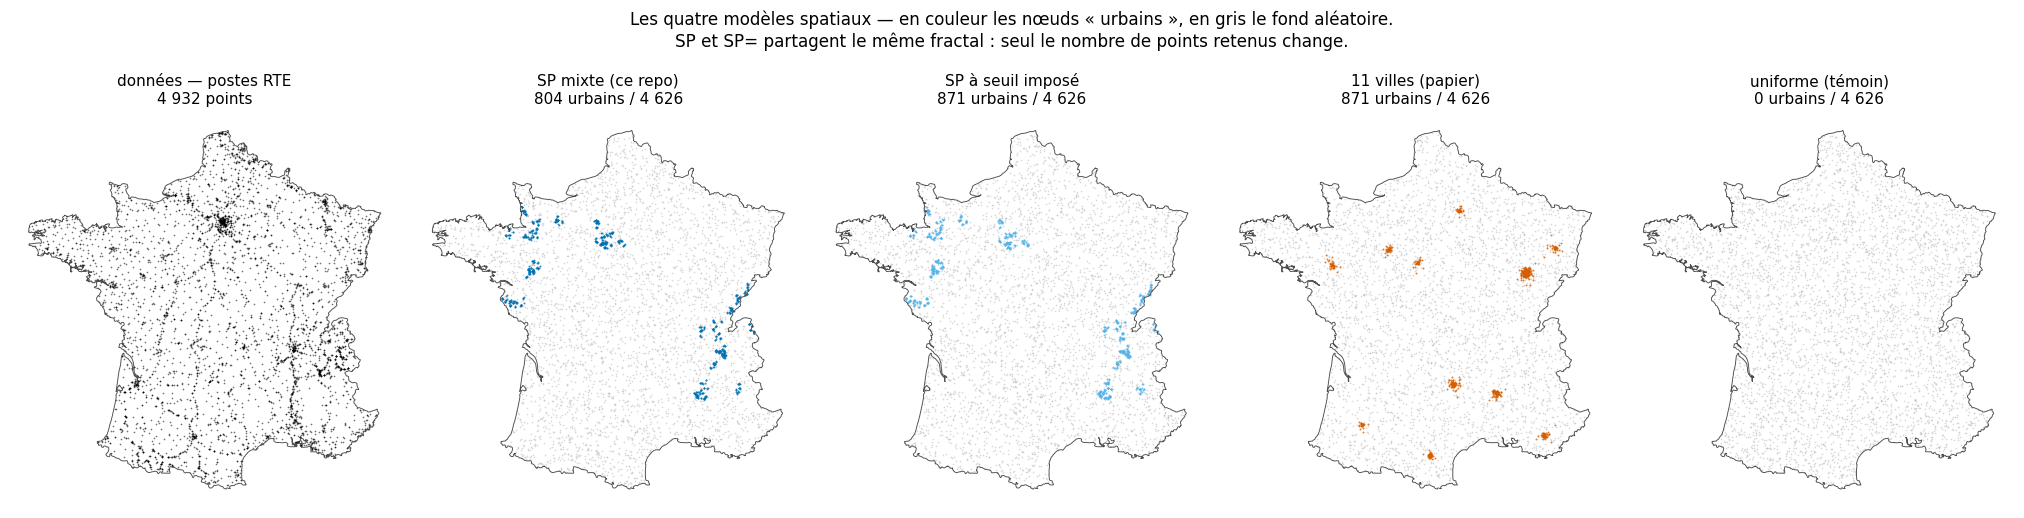

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(18.5, 4.4))
bnd = ld["gdf_edge"].boundary

ax = axes[0]
bnd.plot(ax=ax, color="0.3", lw=0.6)
ax.scatter(ld["xy_metric"][:, 0], ld["xy_metric"][:, 1], s=1.2, c=C["rte"], alpha=.55,
           linewidths=0)
ax.set_title(f"données — postes RTE\n{ld['N_real']:,} points".replace(",", " "),
             fontsize=10)

for ax, m in zip(axes[1:], MODELS):
    xy, iu = POS[m][0]
    bnd.plot(ax=ax, color="0.3", lw=0.6)
    ax.scatter(xy[~iu, 0], xy[~iu, 1], s=1.2, c="0.75", alpha=.6, linewidths=0)
    ax.scatter(xy[iu, 0], xy[iu, 1], s=1.6, c=C[m], alpha=.8, linewidths=0)
    ax.set_title(f"{LBL[m]}\n{iu.sum():,} urbains / {len(xy):,}".replace(",", " "),
                 fontsize=10)

for ax in axes:
    ax.set_aspect("equal"); ax.axis("off")
fig.suptitle("Les quatre modèles spatiaux — en couleur les nœuds « urbains », en gris le "
             "fond aléatoire.\nSP et SP= partagent le même fractal : seul le nombre de "
             "points retenus change.", fontsize=11, y=1.06)
plt.tight_layout()
fig.savefig(ROOT / "out" / "06_nuages.pdf", bbox_inches="tight")
plt.show()

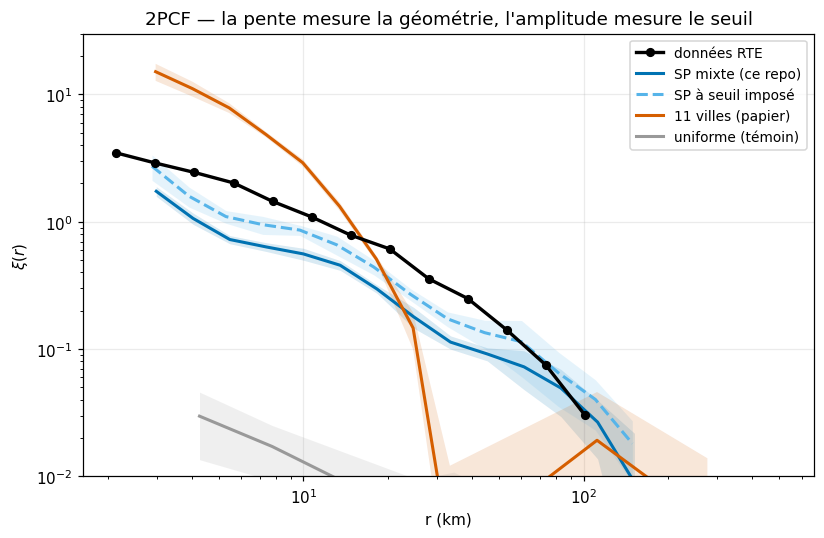

                               γ    ⟨ξ_mod/ξ_data⟩
SP mixte (ce repo)         0.861              0.50
SP à seuil imposé          0.865              0.72
11 villes (papier)         1.869              2.42
uniforme (témoin)          1.160              0.01
données RTE                0.939              1.00

(ξ ≤ 0 masqué : au-delà de ~100 km la corrélation devient négative pour tous les modèles, c'est l'effet de la frontière du territoire.)


In [7]:
# 2PCF : le mélange SP reproduit-il la corrélation des postes RTE ?
_cache_pcf = CACHE / f"pcf_models_M{len(MODELS)}.joblib"
if _cache_pcf.exists():
    PCF = joblib.load(_cache_pcf)
else:
    t0 = time.time()
    PCF = {}
    for m in MODELS:
        xis = []
        for s in range(4):
            xy_n, _ = su.normalize_coords(POS[m][s][0], ld["bounds"])
            r_k, xi_k = su.compute_2pcf_norm(xy_n, ld["geom_norm"])
            xis.append(xi_k)
        PCF[m] = (r_k, np.mean(xis, axis=0), np.std(xis, axis=0))
    joblib.dump(PCF, _cache_pcf)
    print(f"(2PCF calculées en {time.time()-t0:.0f} s)")

scale_km = ld["scale_m"] / 1e3
fig, ax = plt.subplots(figsize=(7.6, 5.0))
ax.plot(ld["r_data"] * scale_km, np.where(ld["xi_data"] > 0, ld["xi_data"], np.nan),
        "o-", color=C["rte"], lw=2.2, ms=5, label="données RTE", zorder=5)
for m in MODELS:
    r_m, xi_m, xis_m = PCF[m]
    pos = xi_m > 0                          # échelle log : on masque ξ ≤ 0
    ls = "--" if m == "SP20" else "-"
    ax.plot((r_m * scale_km)[pos], xi_m[pos], ls, color=C[m], lw=2, label=LBL[m])
    ax.fill_between((r_m * scale_km)[pos],
                    np.clip(xi_m - xis_m, 1e-3, None)[pos], (xi_m + xis_m)[pos],
                    color=C[m], alpha=.15, lw=0)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_ylim(1e-2, 3e1)
ax.set_xlabel("r (km)"); ax.set_ylabel(r"$\xi(r)$")
ax.set_title("2PCF — la pente mesure la géométrie, l'amplitude mesure le seuil")
ax.legend(fontsize=9)
plt.tight_layout()
fig.savefig(ROOT / "out" / "06_2pcf.pdf", bbox_inches="tight")
plt.show()

# γ : la forme. ⟨ξ_mod/ξ_data⟩ : le niveau, sur les bins où ξ_data est mesurable.
print(f"{'':<24s}{'γ':>8s}{'⟨ξ_mod/ξ_data⟩':>18s}")
for m in MODELS:
    r_m, xi_m, _ = PCF[m]
    g, _ = su.fit_powerlaw_norm(r_m, xi_m)
    xd = np.interp(np.log10(r_m), np.log10(ld["r_data"]),
                   np.nan_to_num(ld["xi_data"]), left=np.nan, right=np.nan)
    sel = np.isfinite(xd) & (xd > 0.05) & (xi_m > 0)
    print(f"{LBL[m]:<24s}{g:>8.3f}{np.mean(xi_m[sel] / xd[sel]):>18.2f}")
print(f"{'données RTE':<24s}{ld['gamma_fit']:>8.3f}{1.0:>18.2f}")
print("\n(ξ ≤ 0 masqué : au-delà de ~100 km la corrélation devient négative pour tous "
      "les modèles, c'est l'effet de la frontière du territoire.)")

**Lecture — la pente mesure la géométrie, l'amplitude mesure le seuil.**

Le mélange SP est le seul des modèles à reproduire la corrélation des postes : **γ = 0,86**
contre 0,94 pour les données. Le modèle à 11 villes donne **γ = 1,87** — sa 2PCF n'a pas la
bonne forme, ses amas sont trop peu nombreux et trop compacts pour produire une loi de
puissance sur trois décades ; le témoin uniforme, γ = 1,16, ne corrèle que par effet de
frontière. **C'est le seul endroit du notebook où les modèles se distinguent nettement** —
retenir ce contraste pour la § 6.

Les deux variantes SP partagent le même arbre fractal, et cela se voit : leur pente est la
même à 0,5 % près (**0,861** contre **0,865**). Ce qui bouge, c'est le niveau —
⟨ξ_mod/ξ_data⟩ passe de **0,50 à 0,72**, soit ×1,44 pour un rapport de fractions
(0,200/0,172)² = **1,35**. Le mélange se comporte donc exactement comme le prédit
ξ_mix = f²·ξ_SP, et **la 2PCF sépare proprement les deux questions** : sa pente contraint la
géométrie des amas, son amplitude contraint leur poids dans le nuage. C'est la seule
observable de ce notebook qui contraigne le seuil — les pertes Joule, on le verra au § 6,
n'y sont pas sensibles du tout.

Conséquence directe : **à 20 % de nœuds urbains — la valeur du papier — le mélange SP reste
sous les données d'un facteur 1,4**. Recoller à ξ_data demanderait f ≈ 0,24, soit ~1 100
nœuds structurés. C'est le même chiffre que donne la calibration ρ une fois corrigé son
biais d'interpolation (√ρ = 0,26 au lieu de 0,18) : les deux routes tombent au même endroit.
Le vrai seuil est donc **au-dessus** du 0,2 du papier, pas en dessous comme le suggérait le
0,172 émergent.

Le modèle à 11 villes, lui, ne rate pas le niveau mais la **forme** : ⟨ξ_mod/ξ_data⟩ = 2,42
avec γ = 1,87. Il sur-corrèle brutalement à courte portée (les 11 gaussiennes) et ne corrèle
plus du tout au-delà ; aucun réglage de seuil ne le rapprochera des données.

## 4. La croissance — règles inchangées, structure obtenue

`grow_network` reprend mot pour mot les règles de `grown_graph_pref_attach_poly` : un nœud
rural se raccorde à son plus proche voisin déjà placé, un nœud urbain au nœud de **degré
maximal parmi les `nn_nb = 3` plus proches** (attachement préférentiel local), et une
**deuxième** arête est ajoutée avec la probabilité q selon la même règle.

Une correction assumée : **toutes les distances sont métriques**. Le code du papier compare
les nœuds ruraux en degrés (lat/lon) et les urbains en mètres, ce qui rend le voisinage
rural anisotrope — en France 1° de longitude vaut 0,67° de latitude, donc le « plus proche
voisin » rural est biaisé vers le nord-sud. Sur la version en carré (`grown_graph_pa_flux`,
celle qui produit la figure du papier) le problème n'existe pas, les coordonnées y sont
déjà en kilomètres.

In [8]:
Q_SWEEP = np.array([0.05, 0.15, 0.25, q_RTE, 0.45, 0.5577, 0.70, 0.85])
Q_PAPER = 0.5577          # q du papier : compte les circuits multiples (7 206 ternes)

_cache_net = CACHE / f"networks_N{N_RTE}_R{N_RUNS}_M{len(MODELS)}.joblib"
if _cache_net.exists():
    NETS = joblib.load(_cache_net)
    print("réseaux : chargés du cache")
else:
    t0 = time.time()
    NETS = {m: {round(float(q), 4): [pg.grow_network(POS[m][s][0], POS[m][s][1],
                                                    float(q), seed=s)
                                     for s in range(N_RUNS)]
                for q in Q_SWEEP}
            for m in MODELS}
    joblib.dump(NETS, _cache_net)
    print(f"réseaux : {len(MODELS)*len(Q_SWEEP)*N_RUNS} graphes en {time.time()-t0:.0f} s")

qk = round(float(q_RTE), 4)
print(f"\nstructure à q = q_RTE = {q_RTE:.3f}  (moyenne ± σ sur {N_RUNS} tirages)")
print(f"{'':<24s}{'L_tot (km)':>18s}{'⟨k⟩':>8s}{'k_max':>8s}"
      f"{'% culs-de-sac':>15s}{'arête méd. (km)':>18s}")
rows_struct = {}
for m in MODELS:
    Gs = NETS[m][qk]
    L = [pg.total_length_km(G) for G in Gs]
    k = [np.mean([d for _, d in G.degree()]) for G in Gs]
    kmax = [max(d for _, d in G.degree()) for G in Gs]
    dead = [np.mean([d == 1 for _, d in G.degree()]) for G in Gs]
    emed = [np.median([d["length"] for _, _, d in G.edges(data=True)]) / 1e3 for G in Gs]
    rows_struct[m] = dict(L=np.mean(L), Ls=np.std(L), k=np.mean(k), kmax=np.mean(kmax),
                          dead=np.mean(dead), emed=np.mean(emed))
    print(f"{LBL[m]:<24s}{np.mean(L):>11,.0f} ±{np.std(L):>5,.0f}{np.mean(k):>8.2f}"
          f"{np.mean(kmax):>8.0f}{100*np.mean(dead):>14.1f}%{np.mean(emed):>18.1f}"
          .replace(",", " "))
deg_rte = np.array([d for _, d in G_rte.degree()])
elen_rte = np.array([d["length"] for _, _, d in G_rte.edges(data=True)])
rows_struct["RTE"] = dict(L=pg.total_length_km(G_rte), Ls=0.0, k=deg_rte.mean(),
                          kmax=deg_rte.max(), dead=(deg_rte == 1).mean(),
                          emed=np.median(elen_rte) / 1e3)
r = rows_struct["RTE"]
print(f"{'réseau RTE réel':<24s}{r['L']:>11,.0f}{'':>6s}{r['k']:>8.2f}{r['kmax']:>8.0f}"
      f"{100*r['dead']:>14.1f}%{r['emed']:>18.1f}".replace(",", " "))

réseaux : chargés du cache

structure à q = q_RTE = 0.356  (moyenne ± σ sur 8 tirages)
                                L_tot (km)     ⟨k⟩   k_max  % culs-de-sac   arête méd. (km)
SP mixte (ce repo)           75 376 ±1 092    2.72      23          29.7%               8.4
SP à seuil imposé            74 612 ±  666    2.72      24          30.1%               8.2
11 villes (papier)           73 459 ±  856    2.72      26          29.9%               8.2
uniforme (témoin)            78 124 ±1 140    2.72      15          26.2%               8.9
réseau RTE réel              87 913          2.71      24          29.0%               9.3


In [9]:

# ---------------------------------------------------------------------------
# Le « growth model standard » du papier (fig. 6), sur toute la plage de q.
# On ne le ré-implémente pas et on ne l'adapte pas : on fait tourner
# `grown_graph_pa_flux` telle quelle, et on lui prend ses pertes par arête.
#
# C'est nécessaire parce que le modèle du papier porte **trois** choix
# verrouillés les uns aux autres, qu'on ne peut pas reprendre séparément :
#   1. les injections rangées par indice de nœud       (`queue_power.pop()`)
#   2. les tensions rangées par ordre de création      (`queue_voltage.pop()`)
#   3. son propre spectre de tensions, régénéré aux proportions
#      taux63/taux90/taux225 sur int(N_edges)+1 créneaux avec une marge 5σ —
#      les derniers créneaux 63 kV ne sont donc jamais dépilés.
#
# Vérifié sur une réalisation à q = 0,5577 (les quatre nombres ci-dessous
# sortent tous du **même** graphe, celui du papier) :
#   code du papier ................................................ 3,753 %
#   dc_losses, P rangé, spectre du papier, voltage_rule="time" .... 3,753 %  ✓
#   dc_losses, P rangé, spectre RÉEL (6 272 lignes),      "time" .. 4,539 %
#   dc_losses, P rangé, spectre du papier,                "flow" .. 2,174 %
# Reprendre une file sans l'autre, ou le spectre réel au lieu du sien, change
# donc le résultat d'un facteur ~2 : d'où le choix de faire tourner son code.
# ---------------------------------------------------------------------------
import multiprocessing as mp

_PAPER_NS = {}


def _paper_ns():
    """Namespace du script du papier, chargé une fois par processus."""
    if "ns" not in _PAPER_NS:
        scripts = (ROOT / "data" / "tgm" / "scripts").resolve()
        src_ = str((ROOT / "data" / "tgm" / "src").resolve())
        if src_ not in sys.path:
            sys.path.insert(0, src_)
        code = (scripts / "build_energy_estimates.py").read_text().split("Nit = 10")[0]
        cwd = os.getcwd()
        try:
            os.chdir(scripts)
            ns = {"__name__": "not_main"}
            with open(os.devnull, "w") as dn, contextlib.redirect_stdout(dn), \
                 contextlib.redirect_stderr(dn):
                exec(compile(code, "build_energy_estimates.py", "exec"), ns)
        finally:
            os.chdir(cwd)
        _PAPER_NS["ns"] = ns
    return _PAPER_NS["ns"]


def _paper_one(args):
    """Une réalisation : pertes par arête, tension et longueur de chaque arête, degrés."""
    import random as _r
    import networkx as nx
    q, seed = args
    ns = _paper_ns()
    _r.seed(seed); np.random.seed(seed)
    with open(os.devnull, "w") as dn, contextlib.redirect_stdout(dn), \
         contextlib.redirect_stderr(dn):
        G = ns["grown_graph_pa_flux"](p_growth=float(q), preferential_attachment=True)
    Jd = nx.get_edge_attributes(G, "imped_weight_min")
    e = list(Jd)
    return (round(float(q), 4), seed,
            dict(J=np.array([Jd[k] for k in e], dtype=float),
                 U=np.array([G.edges[k]["Voltage"] for k in e], dtype=float),
                 L=np.array([G.edges[k]["length_in_m"] for k in e], dtype=float),
                 deg=np.array([d for _, d in G.degree()], dtype=int)))


_cache_gm = CACHE / "paper_growth_model.joblib"
if _cache_gm.exists():
    PAPER = joblib.load(_cache_gm)
    print("modèle du papier : chargé du cache")
else:
    t0 = time.time()
    jobs = [(float(q), s) for q in Q_SWEEP for s in range(N_RUNS)]
    with mp.Pool(min(12, mp.cpu_count())) as pool:      # ~2 min sur 12 cœurs
        PAPER = {(q, s): d for q, s, d in pool.map(_paper_one, jobs, chunksize=1)}
    joblib.dump(PAPER, _cache_gm, compress=3)
    print(f"modèle du papier : {len(jobs)} réalisations en {time.time()-t0:.0f} s")

# pertes totales, en % de la puissance installée — la courbe de la fig. 6
J_GM = {}
for q in Q_SWEEP:
    k = round(float(q), 4)
    v = [100 * PAPER[(k, s)]["J"].sum() / Ptot for s in range(N_RUNS)]
    J_GM[k] = (float(np.mean(v)), float(np.std(v)))

# vérification du portage : mon `grow_network` (modèle « 11 villes ») contre le
# code du papier, à q = q_RTE, sur les observables de structure du § 4
_gL = [PAPER[(qk, s)]["L"].sum() / 1e3 for s in range(N_RUNS)]
_gd = [PAPER[(qk, s)]["deg"] for s in range(N_RUNS)]
_ge = [np.median(PAPER[(qk, s)]["L"]) / 1e3 for s in range(N_RUNS)]
print(f"\nportage du modèle « 11 villes » — mon `grow_network` contre le code du papier"
      f"   (q = q_RTE, {N_RUNS} tirages)")
print(f"{'':<24s}{'L_tot (km)':>18s}{'⟨k⟩':>8s}{'k_max':>8s}"
      f"{'% culs-de-sac':>15s}{'arête méd. (km)':>18s}")
r = rows_struct["ORI"]
print(f"{'  ré-implémentation':<24s}{r['L']:>11,.0f} ±{r['Ls']:>5,.0f}{r['k']:>8.2f}"
      f"{r['kmax']:>8.0f}{100*r['dead']:>14.1f}%{r['emed']:>18.1f}".replace(",", " "))
print(f"{'  code du papier':<24s}{np.mean(_gL):>11,.0f} ±{np.std(_gL):>5,.0f}"
      f"{np.mean([d.mean() for d in _gd]):>8.2f}{np.mean([d.max() for d in _gd]):>8.0f}"
      f"{100*np.mean([(d == 1).mean() for d in _gd]):>14.1f}%{np.mean(_ge):>18.1f}"
      .replace(",", " "))
print(f"\npertes du modèle du papier (son code, ses deux files) :")
print(f"  à q = q_RTE  = {q_RTE:.4f} : {J_GM[qk][0]:.2f} ± {J_GM[qk][1]:.2f} %")
_kp = round(float(Q_PAPER), 4)
print(f"  à q = q papier = {Q_PAPER:.4f} : {J_GM[_kp][0]:.2f} ± {J_GM[_kp][1]:.2f} %"
      f"   (publié par RTE : {pg.RTE_PUBLISHED_LOSS_PCT:.2f} %)")


modèle du papier : chargé du cache

portage du modèle « 11 villes » — mon `grow_network` contre le code du papier   (q = q_RTE, 8 tirages)
                                L_tot (km)     ⟨k⟩   k_max  % culs-de-sac   arête méd. (km)
  ré-implémentation          73 459 ±  856    2.72      26          29.9%               8.2
  code du papier             73 081 ±  773    2.72      22          29.3%               8.1

pertes du modèle du papier (son code, ses deux files) :
  à q = q_RTE  = 0.3558 : 4.66 ± 0.38 %
  à q = q papier = 0.5577 : 3.47 ± 0.27 %   (publié par RTE : 3.38 %)


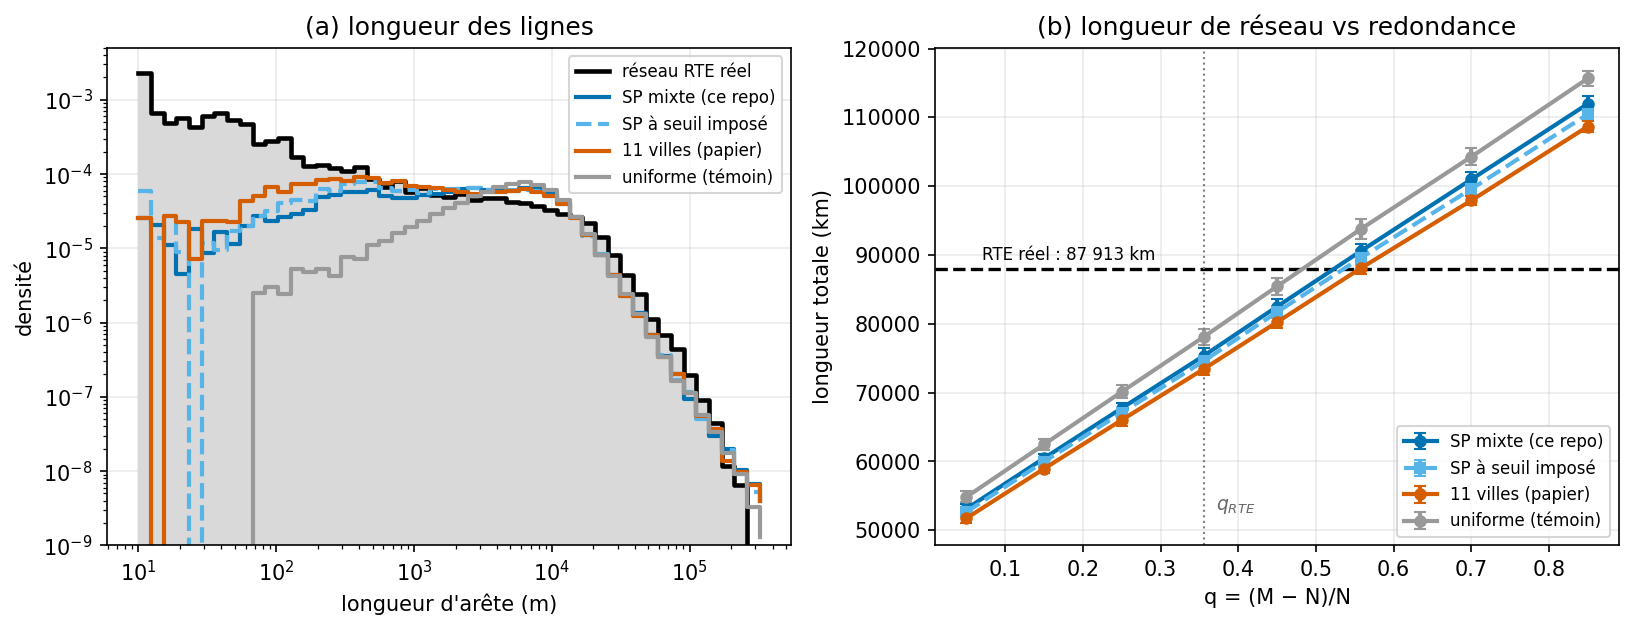

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))

# (b) longueurs d'arêtes
ax = axes[0]
lb = np.logspace(1, 5.6, 51); lx = lb[:-1]
ax.fill_between(lx, np.histogram(elen_rte, bins=lb, density=True)[0], 1e-10,
                step="post", color="0.85", lw=0)
ax.step(lx, np.histogram(elen_rte, bins=lb, density=True)[0], where="post",
        color=C["rte"], lw=2.2, label="réseau RTE réel")
for m in MODELS:
    e = np.concatenate([[d["length"] for _, _, d in G.edges(data=True)]
                        for G in NETS[m][qk]])
    ax.step(lx, np.histogram(e, bins=lb, density=True)[0], where="post",
            color=C[m], lw=2, ls="--" if m == "SP20" else "-", label=LBL[m])
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(1e-9, 5e-3)
ax.set_xlabel("longueur d'arête (m)"); ax.set_ylabel("densité")
ax.set_title("(a) longueur des lignes"); ax.legend(fontsize=8)

# (c) longueur totale vs q
ax = axes[1]
for m in MODELS:
    st = [[pg.total_length_km(G) for G in NETS[m][round(float(q), 4)]] for q in Q_SWEEP]
    ax.errorbar(Q_SWEEP, [np.mean(v) for v in st], yerr=[np.std(v) for v in st],
                fmt="s--" if m == "SP20" else "o-", color=C[m], lw=2, ms=5, capsize=3,
                label=LBL[m])
L_rte = pg.total_length_km(G_rte)
ax.axhline(L_rte, color=C["rte"], lw=1.6, ls="--")
ax.annotate(f"RTE réel : {L_rte:,.0f} km".replace(",", " "), xy=(0.07, L_rte),
            xytext=(0.07, L_rte * 1.015), fontsize=8, color=C["rte"])
ax.axvline(q_RTE, color="0.5", lw=1, ls=":")
ax.annotate("$q_{RTE}$", xy=(q_RTE, 5.3e4), xytext=(q_RTE + .015, 5.3e4), fontsize=9,
            color="0.4")
ax.set_xlabel("q = (M − N)/N"); ax.set_ylabel("longueur totale (km)")
ax.set_title("(b) longueur de réseau vs redondance"); ax.legend(fontsize=8, loc="lower right")

plt.tight_layout()
fig.savefig(ROOT / "out" / "06_topologie.pdf", bbox_inches="tight")
plt.show()

**Lecture.** Les quatre modèles produisent la même topologie au premier ordre — c'est
attendu, les règles de connexion sont identiques et q est imposé. Le tableau ci-dessus le
dit en chiffres : degré moyen 2,72 contre 2,71 pour RTE, longueur d'arête médiane 8,2-8,9 km
contre 9,3 km, fraction de culs-de-sac 29,7-30,1 % contre 29,0 %. **La distribution des degrés mérite mieux qu'un panneau** : elle est imposée au premier
ordre par q et par la règle de raccordement, les quatre modèles s'y ressemblent beaucoup,
et l'œil ne tranche pas. Le § 4.1 la teste quantitativement — c'est la seule observable
topologique du notebook qui sépare « avec amas » de « sans amas ». Le seul écho visible ici
de la structure urbaine est le degré maximal (23 / 24 / 26 pour les trois modèles agglomérés
et 24 pour RTE, contre 15 pour le témoin) : l'attachement préférentiel n'agit que sur les
nœuds urbains, sans eux pas de hub. Les deux panneaux tracés ici portent donc tous deux sur
les **longueurs**.

**Le panneau (a) est celui qui porte l'information.** Les modèles sous-produisent tous les
liaisons très courtes : **13,3 %** des lignes RTE font moins d'un kilomètre, contre 7,4 %
pour les 11 villes, 5,9 % pour SP=, 4,7 % pour SP et **1,0 %** pour le témoin uniforme.
L'ordre suit exactement le degré d'agglomération des modèles, et **le réseau réel est plus
aggloméré que tous** — c'est le même message que l'amplitude de la 2PCF au § 3, lu sur une
autre observable. Les longues liaisons, elles, sont bien reproduites (2,0-2,1 % au-delà de
50 km contre 3,6 % pour RTE).

**Panneau (b) — longueur totale.** Elle est ~14 % sous celle de RTE à q_RTE (75 400 km pour
SP, 74 600 pour SP=, 73 500 pour les 11 villes, 78 100 pour le témoin, contre 87 900). Elle
croît linéairement en q et croise la valeur réelle à q = 0,52 / 0,53 / 0,56 / 0,48 —
c'est-à-dire autour du q = 0,56 du papier, qui compte les circuits multiples : cohérent avec
le fait que la longueur publiée additionne des liaisons doublées que le modèle représente par
une arête unique. Le témoin uniforme est systématiquement le plus long (pas d'amas ⇒ des
sauts au plus proche voisin plus longs), ce qui pèsera sur ses pertes au § 6.


### 4.1 Test sur les distributions de degré

Le tableau du § 4 compare des moyennes ; il ne dit pas si les *distributions* de degré
diffèrent, ni de combien. On teste ici les cinq topologies les unes contre les autres et
contre RTE, sur la loi P(k) tronquée à k ≥ 9.

La difficulté est que N = 4 626 : à cette taille, n'importe quel test d'ajustement rejette
tout. Le χ² n'est donc pas l'information utile — on le donne pour mémoire. Ce qui compte est
la **taille d'effet rapportée au bruit propre du modèle** :

- distance en **variation totale** TV(P, Q) = ½ Σ_k |P(k) − Q(k)| — bornée par 1, lisible
  directement comme « la fraction des nœuds qu'il faudrait déplacer d'une classe de degré à
  une autre » ;
- **plancher de bruit** : la TV moyenne entre deux tirages *du même* modèle (28 paires).
  C'est l'unité naturelle. Un écart au réseau réel de 7 fois le plancher est massif ; un
  écart entre deux modèles de 1 fois le plancher signifie qu'ils sont indiscernables.

Le modèle du papier est inclus tel quel (son propre code), ce qui teste du même coup la
ré-implémentation de la règle de croissance utilisée pour les quatre autres.


loi des degrés P(k), en % des nœuds   (q = q_RTE, 8 tirages)

                                      1      2      3      4      5      6      7      8     ≥9     ⟨k⟩
SP mixte (ce repo)                 29.7   29.5   16.8   10.0    5.8    3.4    1.9    1.0    2.0    2.72
SP à seuil imposé                  30.1   29.6   16.5    9.7    5.8    3.2    1.9    1.1    2.1    2.72
11 villes (papier)                 29.9   29.5   16.9    9.8    5.5    3.5    2.0    1.2    1.8    2.72
uniforme (témoin)                  26.2   30.5   18.3   11.2    6.3    3.4    1.9    0.9    1.2    2.72
growth model standard (papier)     29.3   29.5   17.0   10.1    5.9    3.4    1.9    1.0    1.9    2.72
RTE réel                           29.0   30.4   25.2    4.8    2.5    1.6    1.6    1.4    3.5    2.71

                                   TV(modèle, RTE)  bruit intra   rapport   χ² (ddl 9)          p
SP mixte (ce repo)                   0.1135 ±0.0050       0.0161      7.0×          614   1.8e-126
SP à seuil i

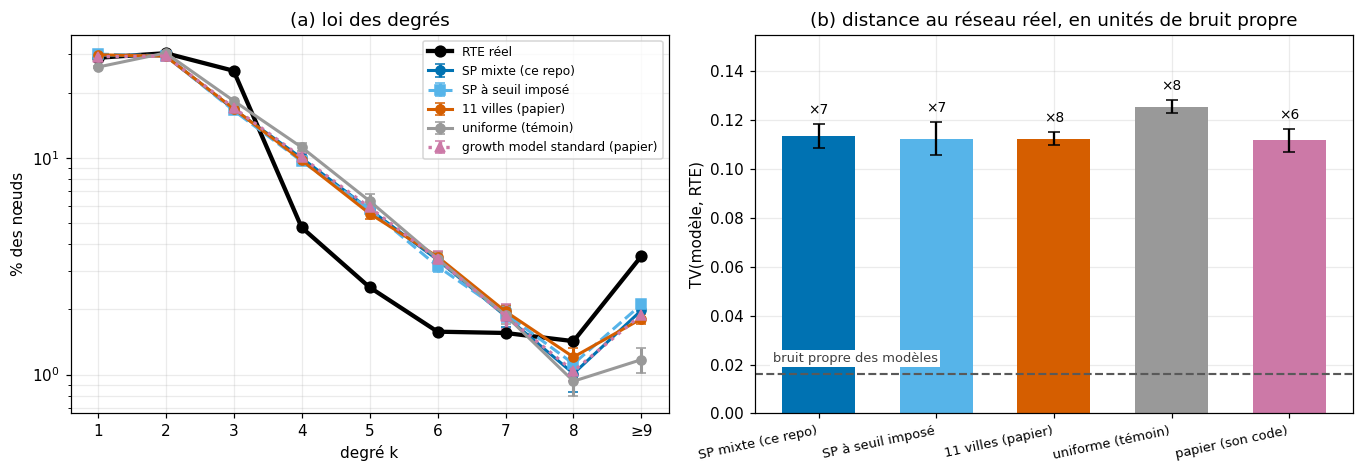

In [11]:
import itertools
from scipy import stats

KMAX = 9                                   # classes 1, 2, … 8, ≥9
KLAB = [str(k) for k in range(1, KMAX)] + [f"≥{KMAX}"]


def deg_pmf(deg):
    d = np.clip(np.asarray(deg), 1, KMAX)
    return np.bincount(d, minlength=KMAX + 1)[1:].astype(float) / len(d)


def tv(a, b):
    """Distance en variation totale entre deux lois discrètes."""
    return 0.5 * np.abs(a - b).sum()


DEG = {m: [np.array([d for _, d in G.degree()]) for G in NETS[m][qk]] for m in MODELS}
DEG["GM"] = [PAPER[(qk, s)]["deg"] for s in range(N_RUNS)]
DEG["RTE"] = [np.array([d for _, d in G_rte.degree()])]
PK = {k: np.array([deg_pmf(d) for d in v]) for k, v in DEG.items()}
DKEYS = list(MODELS) + ["GM"]
DLBL = dict(LBL, GM="growth model standard (papier)", RTE="RTE réel")
C["GM"] = C["warn"]        # le modèle du papier : rose Okabe-Ito, le noir reste à RTE

print(f"loi des degrés P(k), en % des nœuds   (q = q_RTE, {N_RUNS} tirages)\n")
print(f"{'':<32s}" + "".join(f"{l:>7s}" for l in KLAB) + f"{'⟨k⟩':>8s}")
for k in DKEYS + ["RTE"]:
    mu = PK[k].mean(0)
    print(f"{DLBL[k]:<32s}" + "".join(f"{100*x:>7.1f}" for x in mu)
          + f"{np.mean([d.mean() for d in DEG[k]]):>8.2f}")

# plancher de bruit : TV entre deux tirages du même modèle
intra = {m: (lambda v: (np.mean(v), np.std(v)))(
             [tv(PK[m][i], PK[m][j])
              for i, j in itertools.combinations(range(N_RUNS), 2)])
         for m in DKEYS}

print(f"\n{'':<32s}{'TV(modèle, RTE)':>18s}{'bruit intra':>13s}"
      f"{'rapport':>10s}{'χ² (ddl 9)':>13s}{'p':>11s}")
n_rte = len(DEG["RTE"][0])
TVR = {}
for m in DKEYS:
    v = [tv(PK[m][i], PK["RTE"][0]) for i in range(N_RUNS)]
    o = np.round(PK[m].mean(0) * n_rte); e = PK["RTE"][0] * n_rte
    G2 = 2 * np.nansum(np.where(o > 0, o * np.log(o / e), 0.0))
    TVR[m] = (np.mean(v), np.std(v))
    print(f"{DLBL[m]:<32s}{np.mean(v):>11.4f} ±{np.std(v):>5.4f}"
          f"{intra[m][0]:>13.4f}{np.mean(v)/intra[m][0]:>9.1f}×"
          f"{G2:>13.0f}{stats.chi2.sf(G2, KMAX):>11.1e}")

print("\nTV entre modèles (moyenne sur les 64 paires de tirages) ; "
      "à comparer au bruit intra ≈ 0,016")
print(f"{'':<32s}" + "".join(f"{m:>9s}" for m in DKEYS))
TVM = {}
for a in DKEYS:
    row = ""
    for b in DKEYS:
        if a == b:
            row += f"{'—':>9s}"; continue
        TVM[(a, b)] = np.mean([tv(PK[a][i], PK[b][j])
                               for i in range(N_RUNS) for j in range(N_RUNS)])
        row += f"{TVM[(a, b)]:>9.4f}"
    print(f"{DLBL[a]:<32s}" + row)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4))
ax = axes[0]
xs = np.arange(1, KMAX + 1)
for k in DKEYS:
    mu, sd = PK[k].mean(0), PK[k].std(0)
    ax.errorbar(xs, 100 * mu, yerr=100 * sd,
                fmt="s--" if k == "SP20" else ("^:" if k == "GM" else "o-"),
                color=C[k], lw=2.2 if k == "GM" else 2,
                ms=6, capsize=3, label=DLBL[k])
ax.plot(xs, 100 * PK["RTE"][0], "o-", color=C["rte"], lw=2.8, ms=7, label="RTE réel")
ax.set_yscale("log"); ax.set_xticks(xs); ax.set_xticklabels(KLAB)
ax.set_xlabel("degré k"); ax.set_ylabel("% des nœuds")
ax.set_title("(a) loi des degrés"); ax.legend(fontsize=8); ax.grid(alpha=.25, which="both")

ax = axes[1]
xs2 = np.arange(len(DKEYS))
ax.bar(xs2, [TVR[m][0] for m in DKEYS], yerr=[TVR[m][1] for m in DKEYS],
       color=[C[m] for m in DKEYS], capsize=4, width=.62)
ax.axhline(np.mean([intra[m][0] for m in DKEYS]), color="0.35", lw=1.4, ls="--")
ax.annotate("bruit propre des modèles",
            xy=(0.03, np.mean([intra[m][0] for m in DKEYS]) + .005),
            xycoords=("axes fraction", "data"), fontsize=8.5, color="0.25",
            bbox=dict(fc="white", ec="none", pad=1.5))
for i, m in enumerate(DKEYS):
    ax.annotate(f"×{TVR[m][0]/intra[m][0]:.0f}", (i, TVR[m][0] + TVR[m][1] + .004),
                ha="center", fontsize=9)
ax.set_xticks(xs2)
ax.set_xticklabels([LBL[m] if m in LBL else "papier (son code)" for m in DKEYS],
                   fontsize=8.5, rotation=12, ha="right")
ax.set_ylim(0, .155); ax.set_ylabel("TV(modèle, RTE)")
ax.set_title("(b) distance au réseau réel, en unités de bruit propre")
ax.grid(alpha=.25, axis="y")

plt.tight_layout()
fig.savefig(ROOT / "out" / "06_degres.pdf", bbox_inches="tight")
plt.show()


**Lecture.**

**Le portage est validé.** Le modèle du papier tourné avec *son* code et ma
ré-implémentation « 11 villes » sont à **TV = 0,018** l'un de l'autre, pour un bruit propre
de 0,014 à 0,018 : ils sont indiscernables au niveau du bruit d'échantillonnage. Le tableau
de structure de la cellule précédente dit la même chose (73 100 contre 73 500 km, ⟨k⟩ 2,72
des deux côtés, 29,3 contre 29,9 % de culs-de-sac, arête médiane 8,1 contre 8,2 km ; seul le
degré maximal diffère, 22 contre 26, mais c'est un maximum sur 4 626 tirages). Tout ce qui suit sur
les quatre modèles vaut donc aussi pour le modèle du papier, et réciproquement.

**Les cinq modèles ratent RTE de la même façon, très largement.** TV = 0,112 à 0,126, soit
**6 à 8 fois leur propre bruit** ; χ² de 575 à 767 pour 9 degrés de liberté, p < 10⁻¹¹⁸. Il
ne s'agit pas d'un écart marginal : il faudrait déplacer **11 à 13 % des nœuds** d'une classe
de degré à une autre pour passer d'un modèle aux données. Et l'écart va dans le même sens
pour tous. Le mécanisme se lit sur le panneau (a) :

| | k = 3 | k = 4 | k ≥ 9 |
|---|---|---|---|
| RTE réel | **25,2 %** | **4,8 %** | **3,5 %** |
| modèles agglomérés | 16,5-17,0 % | 9,7-10,1 % | 1,8-2,1 % |
| témoin uniforme | 18,3 % | 11,2 % | 1,2 % |

Le vrai réseau **concentre** ses nœuds sur le degré 3 et se vide au-delà, avec en plus une
poignée de très gros hubs. Les modèles étalent au contraire une décroissance régulière de
k = 3 à k = 8. C'est structurel : la règle de croissance ajoute un nœud avec **une** arête,
plus une seconde avec probabilité q, ce qui produit une loi géométrique en k — alors que le
réseau réel est un objet d'ingénieur, où le poste à trois départs est le motif standard. La
distribution des degrés n'est pas quelque chose que cette famille de modèles peut atteindre
en ajustant q.

**Mais — et c'est le résultat utile — elle discrimine, là où les pertes Joule ne
discriminaient pas.** Les quatre modèles agglomérés (SP, SP=, 11 villes, papier) sont à
TV = 0,016 à 0,021 les uns des autres, c'est-à-dire **exactement au niveau du bruit** : ni
la géométrie fractale, ni le seuil, ni le nombre d'amas ne laissent la moindre trace dans
P(k). Le **témoin uniforme**, lui, s'en détache à TV = 0,043 à 0,052, soit **3 fois le
bruit** — un effet net et reproductible. C'est la première observable de ce notebook qui
sépare franchement « avec amas » de « sans amas ».

**Et elle les sépare dans le bon sens.** Le témoin uniforme est aussi le **plus loin** de RTE
(0,126 contre 0,112-0,113) : sans amas, on a trop de degré 2-4 et pas de hub du tout
(1,2 % de k ≥ 9 contre 3,5 % dans les données). L'agglomération pousse donc P(k) dans la
bonne direction — elle ne fait qu'un dixième du chemin, mais elle le fait, et de façon
mesurable. Sur les pertes Joule (§ 6) le témoin sans ville était au contraire *aussi bon*
que les modèles agglomérés : les deux observables ne classent pas les modèles de la même
façon, et c'est la loi des degrés qui a raison de les distinguer.

**Ce que ça vaut comme test.** Il est unilatéral : il rejette tous les modèles contre les
données, et il ne départage que « amas / pas d'amas ». Pour départager les géométries d'amas
entre elles, la loi des degrés est aveugle — il faut aller chercher des observables qui
mélangent topologie et distance (§ 7), ou la 2PCF des positions elle-même (§ 3), qui est la
seule à séparer les quatre modèles sans ambiguïté.


## 5. Des métadonnées aux injections

Le load-flow a besoin d'un vecteur d'injections nettes P_i = production_i − consommation_i,
de somme nulle. Le papier le construit par une chaîne de modélisation — densité de population
attribuée aux nœuds, convertie en consommation par une loi `pop_i ** κ`, complétée par une
production tirée au hasard — dont chaque maillon ajoute une hypothèse et dont le paramètre κ
n'est fixé par aucune donnée.

**Ce notebook ne suit pas cette voie.** Aucune métadonnée n'est modélisée : on prend le
vecteur d'injections **réel**, celui des 4 626 postes RTE, publié, production et consommation
déjà appariées poste par poste — et on ne fait varier que **la façon de le poser sur les
nœuds du modèle**. Deux placements, qui encadrent la question :

| recette | où va la plus grosse injection | couplage position ↔ injection |
|---|---|---|
| **P rangé (papier)** | sur le nœud 0, puis par valeur décroissante | maximal — et **gratuit** |
| **P mélangé** | n'importe où | aucun |

Σ P est conservée dans les deux cas et la marginale est identique, exacte, non modélisée : la
**seule** variable de l'expérience est le couplage.

### Pourquoi la règle du papier n'est pas neutre

`np.sort(P)[::-1]` posé par indice de nœud a l'air d'une convention d'implémentation. Elle
n'en est pas une. Dans un modèle de croissance, l'indice **est** l'ordre de création, et
l'attachement préférentiel fait des premiers nœuds les plus connectés :

> corr(indice de création, degré) = **−0,61**. Degré moyen **8,7** pour les 100 premiers
> nœuds, **5,9** sur les 500 premiers, **1,8** au-delà du 2 000ᵉ.

Ranger les injections par valeur décroissante revient donc à poser les 5,4 GW du plus gros
producteur sur un nœud de degré ~9, et les petites injections sur des feuilles : un couplage
**injection ↔ connectivité** fort, jamais énoncé comme hypothèse, obtenu gratuitement par la
numérotation des nœuds.

Le contrôle est immédiat. Appliquée au **vrai** réseau RTE, dont l'indice de nœud est
arbitraire, la même règle donne **6,34 %** de pertes — contre 3,20 % avec les injections à
leur vraie place, et 4,41 % en les mélangeant. La règle ne transporte donc aucune physique :
elle exploite une propriété du modèle qui n'existe pas dans les données. C'est précisément ce
que la § 6 met en évidence, en la comparant terme à terme au placement neutre.

### La chaîne du papier, reléguée au § 8

Elle n'est pas abandonnée, elle est traitée comme ce qu'elle est — une hypothèse dont on
chiffre le coût. Deux remarques la concernant, mesurées là-bas :

- **κ = 0 n'est pas « la convention des données »**, malgré le raccourci « charge uniforme ».
  Répartir la consommation à parts égales *à l'intérieur de chaque département* donne un
  escalier à 94 marches — de 8,9 à 119,1 MW par poste, plus 766 postes à zéro, CV = 0,72 —
  pas une constante globale. Sur la vraie topologie, production laissée en place, cet
  aplatissement coûte **+0,24 point** de pertes (3,20 → 3,44 %).
- L'écart reste d'ordre deux, cohérent avec var(conso)/var(prod) = **0,0084** : la
  consommation ne porte même pas 1 % de la variance de P, écrasée par la queue de production.
  C'est une raison de plus de travailler sur le vecteur net publié plutôt que de le
  reconstruire.


## 6. Le résultat — pertes Joule contre redondance

Tout est en place : quatre modèles spatiaux × huit valeurs de q × huit tirages × **deux
recettes d'injection**, avec **le même** estimateur, **le même** spectre de tensions (les
6 272 vraies lignes RTE réparties par rang de flux) et **la même** normalisation que la
référence.

In [12]:
# le même vecteur d'injections réel, posé de deux façons opposées
P_ORDERED = np.sort(ref["P"])[::-1]     # attribution du papier : par indice de nœud

RECIPES = ("ordered", "shuffle")
RLBL = {"ordered": "P réel rangé par indice — la règle d'injection du papier",
        "shuffle": "P réel mélangé — position au hasard"}
RSHORT = {"ordered": "P rangé/indice", "shuffle": "P mélangé"}


def model_P(m, s, recipe):
    """Vecteur d'injections du modèle `m`, tirage `s`, selon la recette.

    Les deux recettes portent **exactement la même marginale** — celle des
    4 626 postes RTE, production et consommation appariées poste par poste.
    Seule change la façon de la poser sur les nœuds :

    - `ordered` : la plus grosse injection sur le nœud 0, puis par valeur
      décroissante. C'est la règle d'injection du papier (`queue_power.pop()`,
      vérifiée identique au bit près) — mais avec l'estimateur du notebook :
      spectre réel des 6 272 lignes et tensions par rang de flux. Le modèle du
      papier complet, qui y ajoute *sa* file de tensions et *son* spectre, est
      calculé à part au § 4 (`J_GM`). Dans un modèle de croissance
      l'indice **est** l'ordre de création, et l'attachement préférentiel fait
      des premiers nœuds les plus connectés — corr(indice, degré) = −0,61,
      degré moyen 8,7 pour les 100 premiers contre 1,8 au-delà du 2 000ᵉ. La
      règle crée donc gratuitement un couplage injection ↔ connectivité.
    - `shuffle` : permutation aléatoire, aucun couplage.

    Ni l'une ni l'autre n'introduit de métadonnée modélisée ; la chaîne
    population → charge du papier est mesurée à part au § 8.
    """
    if recipe == "shuffle":
        return pg.injections_shuffled(ref["P"], seed=s)
    return P_ORDERED


_cache_j = CACHE / (f"joule_N{N_RTE}_R{N_RUNS}_M{len(MODELS)}_"
                    + "-".join(RECIPES) + ".joblib")
if _cache_j.exists():
    JOULE = joblib.load(_cache_j)
    print("pertes : chargées du cache")
else:
    t0 = time.time()
    JOULE = {}
    for rc in RECIPES:
        for m in MODELS:
            for q in Q_SWEEP:
                k = round(float(q), 4)
                v = [pg.loss_pct(NETS[m][k][s], model_P(m, s, rc), Ptot, ref["volt_mix"])
                     for s in range(N_RUNS)]
                JOULE[(rc, m, k)] = (np.mean(v), np.std(v))
    joblib.dump(JOULE, _cache_j)
    print(f"pertes : {len(RECIPES)*len(MODELS)*len(Q_SWEEP)*N_RUNS} load-flows "
          f"en {time.time()-t0:.0f} s")

# références : la vraie topologie, avec exactement la même recette d'injection
_cache_r = CACHE / ("ref_losses_" + "-".join(RECIPES) + ".joblib")
if _cache_r.exists():
    REF_L = joblib.load(_cache_r)
else:
    REF_L = {}
    REF_L["given"] = pg.loss_pct(G_rte, ref["P"], Ptot, ref["volt_mix"],
                                 voltage_rule="given")
    REF_L["flow"] = pg.loss_pct(G_rte, ref["P"], Ptot, ref["volt_mix"])
    for rc in RECIPES:
        # la référence « rangée » est le contrôle décisif : sur le vrai réseau
        # l'indice de nœud ne veut rien dire, la règle du papier n'y a donc
        # aucun sens physique — on mesure ce qu'elle y donne quand même
        if rc == "shuffle":
            Ps = [pg.injections_shuffled(ref["P"], seed=s) for s in range(N_RUNS)]
        else:
            Ps = [P_ORDERED]
        v = [pg.loss_pct(G_rte, P, Ptot, ref["volt_mix"]) for P in Ps]
        REF_L[rc] = (np.mean(v), np.std(v))
    joblib.dump(REF_L, _cache_r)

print("\nréférences (topologie RTE réelle)")
print(f"  injections réelles EN PLACE, tensions réelles : {REF_L['given']:.2f} %")
print(f"  injections réelles EN PLACE, tensions par flux: {REF_L['flow']:.2f} %")
for rc in RECIPES:
    print(f"  recette « {RSHORT[rc]:<13s} », tensions par flux  : "
          f"{REF_L[rc][0]:.2f} ± {REF_L[rc][1]:.2f} %")
print(f"  publié par RTE                                : "
      f"{pg.RTE_PUBLISHED_LOSS_PCT:.2f} %")

pertes : chargées du cache

références (topologie RTE réelle)
  injections réelles EN PLACE, tensions réelles : 4.74 %
  injections réelles EN PLACE, tensions par flux: 3.20 %
  recette « P rangé/indice », tensions par flux  : 6.34 ± 0.00 %
  recette « P mélangé     », tensions par flux  : 4.41 ± 0.57 %
  publié par RTE                                : 3.38 %


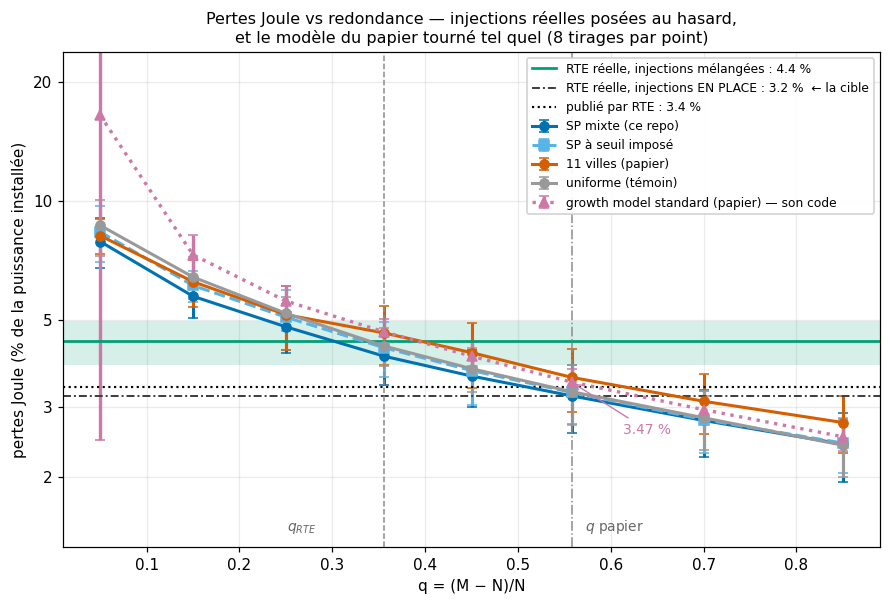

In [13]:
import matplotlib.ticker as mticker

RC_MAIN = "shuffle"          # la recette du notebook : vecteur réel, placement neutre
vals = np.array([JOULE[(rc, m, round(float(q), 4))][0]
                 for rc in RECIPES for m in MODELS for q in Q_SWEEP]
                + [J_GM[round(float(q), 4)][0] for q in Q_SWEEP])
ylo, yhi = 0.75 * vals.min(), 1.45 * vals.max()
ticks = [t for t in (1, 2, 3, 5, 10, 20, 40, 80, 160) if ylo <= t <= yhi]


def _yerr(mu, sd):
    """Barres tronquées vers le bas : l'axe est logarithmique."""
    return np.vstack([np.minimum(sd, 0.85 * mu), sd])


fig, ax = plt.subplots(figsize=(8.2, 5.6))
mu_r, sd_r = REF_L[RC_MAIN]
ax.axhspan(mu_r - sd_r, mu_r + sd_r, color=C["ref"], alpha=.16, lw=0)

for m in MODELS:
    v = np.array([JOULE[(RC_MAIN, m, round(float(q), 4))] for q in Q_SWEEP])
    ax.errorbar(Q_SWEEP, v[:, 0], yerr=_yerr(v[:, 0], v[:, 1]),
                fmt="s--" if m == "SP20" else "o-",
                color=C[m], lw=2, ms=6, capsize=3, label=LBL[m])

# Le modèle de croissance standard du papier (fig. 6), tel quel : son code, ses
# injections rangées par indice de nœud, ses tensions rangées par ordre de
# création, son propre spectre de tensions. Les trois choix sont verrouillés
# ensemble (cf. § 4) — on ne peut pas en reprendre un sans les autres, donc on
# ne démonte rien : on trace ce que le papier trace.
v = np.array([J_GM[round(float(q), 4)] for q in Q_SWEEP])
ax.errorbar(Q_SWEEP, v[:, 0], yerr=_yerr(v[:, 0], v[:, 1]), fmt="^:", color=C["warn"],
            lw=2.2, ms=7, capsize=3,
            label="growth model standard (papier) — son code")

# les trois repères horizontaux, dans la légende plutôt qu'annotés sur la figure
ax.axhline(mu_r, color=C["ref"], lw=1.8,
           label=f"RTE réelle, injections mélangées : {mu_r:.1f} %")
ax.axhline(REF_L["flow"], color="0.25", lw=1.3, ls=(0, (4, 1.5, 1, 1.5)),
           label=f"RTE réelle, injections EN PLACE : {REF_L['flow']:.1f} %  ← la cible")
ax.axhline(pg.RTE_PUBLISHED_LOSS_PCT, color=C["rte"], lw=1.4, ls=":",
           label=f"publié par RTE : {pg.RTE_PUBLISHED_LOSS_PCT:.1f} %")

ax.axvline(q_RTE, color="0.55", lw=1, ls="--")
ax.axvline(Q_PAPER, color="0.55", lw=1, ls="-.")
ax.set_yscale("log"); ax.set_ylim(ylo, yhi)
ax.yaxis.set_major_locator(mticker.FixedLocator(ticks))
ax.yaxis.set_minor_locator(mticker.NullLocator())
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xlabel("q = (M − N)/N")
ax.set_ylabel("pertes Joule (% de la puissance installée)")
ax.grid(alpha=.25, which="both")
# les libellés des verticales en bas (zone vide), ceux des horizontales à gauche
ax.annotate("$q_{RTE}$", xy=(q_RTE, ylo * 1.10), xytext=(q_RTE - .105, ylo * 1.10),
            fontsize=9, color="0.4")
ax.annotate("$q$ papier", xy=(Q_PAPER, ylo * 1.10), xytext=(Q_PAPER + .015, ylo * 1.10),
            fontsize=9, color="0.4")
# le point sur lequel repose l'accord du papier
_kp = round(float(Q_PAPER), 4)
ax.annotate(f"{J_GM[_kp][0]:.2f} %", xy=(Q_PAPER, J_GM[_kp][0]),
            xytext=(Q_PAPER + .055, J_GM[_kp][0] * 0.74), fontsize=9,
            color=C["warn"],
            arrowprops=dict(arrowstyle="->", color=C["warn"], lw=.9))
ax.legend(fontsize=8, loc="upper right", framealpha=.93)
ax.set_title("Pertes Joule vs redondance — injections réelles posées au hasard,\n"
             f"et le modèle du papier tourné tel quel ({N_RUNS} tirages par point)",
             fontsize=10.5)
plt.tight_layout()
fig.savefig(ROOT / "out" / "06_joule_vs_q.pdf", bbox_inches="tight")
plt.show()


In [14]:
print(f"pertes Joule à q = q_RTE = {q_RTE:.3f}   (% de la puissance installée)\n")
print(f"{'':<24s}{'n_urbains':>11s}" + "".join(f"{RSHORT[rc]:>18s}" for rc in RECIPES))
for m in MODELS:
    nu = np.mean([iu.sum() for _, iu in POS[m]])
    line = f"{LBL[m]:<24s}{nu:>11.0f}"
    for rc in RECIPES:
        mu, sd = JOULE[(rc, m, qk)]
        line += f"{mu:>11.2f} ±{sd:>5.2f}"
    print(line)
print("-" * (35 + 18 * len(RECIPES)))
line = f"{'topologie RTE réelle':<24s}{'—':>11s}"
for rc in RECIPES:
    line += f"{REF_L[rc][0]:>11.2f} ±{REF_L[rc][1]:>5.2f}"
print(line + "   ← la référence")
print(f"{'  (injections en place)':<24s}{'—':>11s}{REF_L['flow']:>11.2f}")
print(f"{'  (publié par RTE)':<24s}{'—':>11s}{pg.RTE_PUBLISHED_LOSS_PCT:>11.2f}")

print(f"\ngrowth model standard du papier — son code, ses deux files, son spectre")
print(f"  à q = q_RTE   = {q_RTE:.4f} : {J_GM[qk][0]:>5.2f} ± {J_GM[qk][1]:.2f} %"
      f"   ({(J_GM[qk][0]-pg.RTE_PUBLISHED_LOSS_PCT)/pg.RTE_PUBLISHED_LOSS_PCT:+.0%} "
      f"contre le chiffre publié)")
_kp = round(float(Q_PAPER), 4)
print(f"  à q = q papier = {Q_PAPER:.4f} : {J_GM[_kp][0]:>5.2f} ± {J_GM[_kp][1]:.2f} %"
      f"   ({(J_GM[_kp][0]-pg.RTE_PUBLISHED_LOSS_PCT)/pg.RTE_PUBLISHED_LOSS_PCT:+.0%})"
      f"   ← l'accord de la fig. 6")

print("\nécart au réseau réel soumis à la même recette, en unités de σ :")
for rc in RECIPES:
    mu_r, sd_r = REF_L[rc]
    line = f"  {RSHORT[rc]:<13s} : "
    for m in MODELS:
        mu, sd = JOULE[(rc, m, qk)]
        line += f"{m} {(mu - mu_r) / np.hypot(sd, sd_r):+.1f}σ   "
    print(line)

print("\neffet du seuil, à géométrie fractale identique (SP= contre SP) :")
for rc in RECIPES:
    a, b = JOULE[(rc, "SP", qk)], JOULE[(rc, "SP20", qk)]
    print(f"  {RSHORT[rc]:<13s} : {b[0]-a[0]:+.2f} pt  "
          f"({(b[0]-a[0])/np.hypot(a[1], b[1]):+.1f}σ)")
print("\neffet de la géométrie, à nombre d'urbains identique (SP= contre 11 villes) :")
for rc in RECIPES:
    a, b = JOULE[(rc, "ORI", qk)], JOULE[(rc, "SP20", qk)]
    print(f"  {RSHORT[rc]:<13s} : {b[0]-a[0]:+.2f} pt  "
          f"({(b[0]-a[0])/np.hypot(a[1], b[1]):+.1f}σ)")


pertes Joule à q = q_RTE = 0.356   (% de la puissance installée)

                          n_urbains    P rangé/indice         P mélangé
SP mixte (ce repo)              796       3.44 ± 0.61       4.04 ± 0.63
SP à seuil imposé               923       3.06 ± 0.56       4.25 ± 0.67
11 villes (papier)              923       3.12 ± 0.39       4.63 ± 0.79
uniforme (témoin)                 0       3.49 ± 0.51       4.29 ± 0.48
-----------------------------------------------------------------------
topologie RTE réelle              —       6.34 ± 0.00       4.41 ± 0.57   ← la référence
  (injections en place)           —       3.20
  (publié par RTE)                —       3.38

growth model standard du papier — son code, ses deux files, son spectre
  à q = q_RTE   = 0.3558 :  4.66 ± 0.38 %   (+38% contre le chiffre publié)
  à q = q papier = 0.5577 :  3.47 ± 0.27 %   (+3%)   ← l'accord de la fig. 6

écart au réseau réel soumis à la même recette, en unités de σ :
  P rangé/indice : SP -4.8σ 

**Ce que la figure dit.** Les quatre modèles y sont tracés avec le **placement neutre** — le
vecteur d'injections réel, permuté au hasard. La courbe noire est le **growth model standard
du papier** (fig. 6), obtenue en faisant tourner son code, sans rien lui reprendre ni rien lui
imposer : ses injections rangées par indice, ses tensions rangées par ordre de création, son
propre spectre. Le tableau ci-dessous ajoute, pour les quatre modèles, ce que donne la
**règle d'attribution du papier avec l'estimateur du notebook** (spectre réel, tensions par
rang de flux) — c'est un objet différent de la courbe noire, et la comparaison des deux est
justement le cœur de ce qui suit.

**La courbe noire retrouve le chiffre de RTE — à q = 0,5577.** Le modèle du papier donne
**3,47 ± 0,27 %** à son propre q, contre **3,38 %** publiés : +3 %, l'accord de la fig. 6 est
reproduit à l'identique. Mais à **q_RTE = 0,3558**, le q de la topologie réellement fournie
par RTE, le même modèle donne **4,66 ± 0,38 %**, soit **+38 %**. Entre les deux q la courbe
perd un tiers de sa valeur, et la croise vers q ≈ 0,58. L'accord ne tient donc pas au modèle
seul : il tient à la convention qui compte les **7 206 ternes** plutôt que les 6 272 lignes
du graphe. C'est une convention défendable — le modèle crée une arête par circuit — mais elle
vaut à elle seule tout l'écart, et il faut la dire.

**Le plus instructif : les deux files du papier s'annulent presque exactement.** Sur la
*même* topologie « 11 villes », à q_RTE :

| recette | pertes |
|---|---|
| injections rangées par indice + tensions par rang de flux | **3,12 ± 0,39 %** |
| injections mélangées + tensions par rang de flux | **4,63 ± 0,79 %** |
| le papier : injections rangées + tensions par ordre de création + son spectre | **4,66 ± 0,38 %** |

Ranger les injections fait gagner **1,5 point** (§ 5) ; attribuer les tensions par ordre de
création en fait reperdre **1,5 point**. Le résultat du papier est donc, au hasard près,
celui qu'on obtiendrait en **mélangeant** les injections et en dimensionnant correctement les
tensions. Les deux « astuces » du modèle sont chacune fausses d'un facteur ~1,5, en sens
opposés, et le total tombe juste. C'est exactement pourquoi le total de pertes est une
mauvaise observable de validation, et pourquoi le § 7 va regarder *où* ces pertes se placent.

**Avec le placement neutre, les pertes ne distinguent aucun modèle.** À q_RTE : SP
4,04 ± 0,63 %, SP= 4,25 ± 0,67 %, 11 villes 4,63 ± 0,79 %, témoin uniforme 4,29 ± 0,48 %,
contre **4,41 ± 0,57 %** pour la vraie topologie soumise à la même recette — soit **−0,4σ,
−0,2σ, +0,2σ et −0,2σ**. Les quatre sont dans un mouchoir de poche, **et le témoin sans
aucune ville est le deuxième plus proche de la référence**. À N et q fixés, le niveau de
pertes est piloté par la longueur totale de réseau et la redondance, pas par la géographie
urbaine. C'est ce que le témoin `RAND` sert à révéler — le papier, qui ne le contient pas,
attribue à sa différenciation rural/urbain un accord qu'une géométrie sans aucune ville
obtient tout aussi bien.

**Ranger les injections n'est pas physique.** Le contrôle est dans le tableau : la règle
appliquée au **vrai** réseau RTE, dont l'indice de nœud est arbitraire, donne **6,34 %** —
deux fois la bonne valeur, et pire que le placement au hasard (4,41 %). Elle ne marche que là
où l'indice porte une information : dans un modèle de croissance, où il **est** l'ordre de
création et où l'attachement préférentiel fait des premiers nœuds les plus connectés
(corr(indice, degré) = −0,61 ; degré moyen 8,7 pour les 100 premiers nœuds, 1,8 au-delà du
2 000ᵉ). `np.sort(P)[::-1]` pose les 5,4 GW du plus gros producteur sur un hub et les petites
injections sur des feuilles. Avec cette règle et un estimateur correct, les quatre modèles
descendent à 3,44 / 3,06 / 3,12 / **3,49 %** contre les 3,20 % de la vraie topologie avec ses
vraies injections en place : l'accord devient excellent, **et il l'est autant pour le modèle
sans aucune ville**.

**Ni le nombre d'amas ni leur forme ne sont visibles, dans aucune des deux recettes.** À
géométrie fractale identique, passer de 796 à 923 nœuds structurés (+16 %) déplace les pertes
de **−0,5σ / +0,2σ**. À nombre d'urbains identique, remplacer le fractal auto-similaire par
les 11 gaussiennes du papier donne **−0,1σ / −0,4σ**. Aucun des deux effets n'atteint 0,5σ.
Le § 3 séparait pourtant les modèles sans ambiguïté (γ = 0,86 / 0,87 / 1,87 / 1,16 contre
0,94), et le § 4.1 sépare « avec amas » de « sans amas » à 3σ du bruit, là où les pertes ne
séparent rien : les observables ne mesurent pas la même chose, et c'est la moins physique des
trois qui contraint le moins le modèle spatial.

**Le couplage réel, lui, se mesure.** Sur la *vraie* topologie, avec le *vrai* vecteur
d'injections : **3,20 %** quand chaque poste garde la sienne, **4,41 ± 0,57 %** quand on
permute ce même vecteur au hasard. Le couplage position ↔ injection vaut donc **1,2 point de
pertes, soit +38 %**. C'est l'ordre de grandeur que la règle du papier récupère — mais par un
mécanisme qui n'est pas celui des données : chez lui les grosses injections sont sur les
nœuds les plus **connectés**, alors que dans les données elles sont là où elles sont pour des
raisons géographiques et historiques.

**Décroissance en q.** Les pertes chutent d'un facteur 3 à 4 entre q = 0,05 et q = 0,85
(SP : 7,0 % → 2,1 % rangé, 7,9 % → 2,4 % mélangé ; le modèle du papier : 16,5 % → 2,5 %) :
mailler le réseau ouvre des chemins parallèles, chaque ligne porte moins de flux, et J ∝ P².
La pente est la même pour tous — encore un signe que cette observable mesure la redondance,
pas la géographie. Attention d'ailleurs à q = 0,56 : les modèles y portent **13 % de lignes
de plus** que le réseau réel. La comparaison à topologie donnée n'a de sens qu'à q = q_RTE.


## 7. Où sont les pertes ?

Le total ne dit pas tout : deux réseaux peuvent perdre les mêmes 4 % en les plaçant à des
endroits complètement différents. Comme `dc_losses` renvoie la perte **de chaque arête** — et
comme le code du papier renvoie la sienne (`imped_weight_min`) — on peut regarder la
*répartition* plutôt que la somme. C'est une observable que le papier n'utilise pas.

Trois découpages, tous invariants par renumérotation des nœuds, donc comparables entre des
géométries différentes :

- **(a) concentration** — la courbe de Lorenz des pertes par ligne : quelle fraction des
  pertes est portée par les lignes les plus chargées. Résumée par le coefficient de Gini.
- **(b) par niveau de tension** — pour les quatre modèles du notebook, le spectre des 6 272
  tensions RTE est imposé à l'identique, la comparaison est donc directe. **Le modèle du
  papier fait exception** : il régénère son propre spectre à quatre niveaux et l'attribue par
  ordre de création d'arête (§ 4), et ces deux choix font partie du modèle — on les garde,
  mais sa courbe (b) répond à une question légèrement différente des autres.
- **(c) par longueur de ligne** — les pertes valent R·P²/U² avec R ∝ ℓ : c'est là que la
  différence de structure vue au § 4 (les modèles sous-produisent les liaisons courtes) doit
  se retrouver, ou pas.

Recette : le placement neutre du § 6 pour les quatre modèles, le modèle du papier tourné tel
quel, et le vrai réseau avec ses vraies injections comme cible. Deux contrôles complètent le
tableau : la même topologie « 11 villes » avec les injections rangées mais l'estimateur du
notebook, et la règle « rangée » appliquée au vrai réseau — où l'indice de nœud ne veut rien
dire.


profils de pertes : chargés du cache


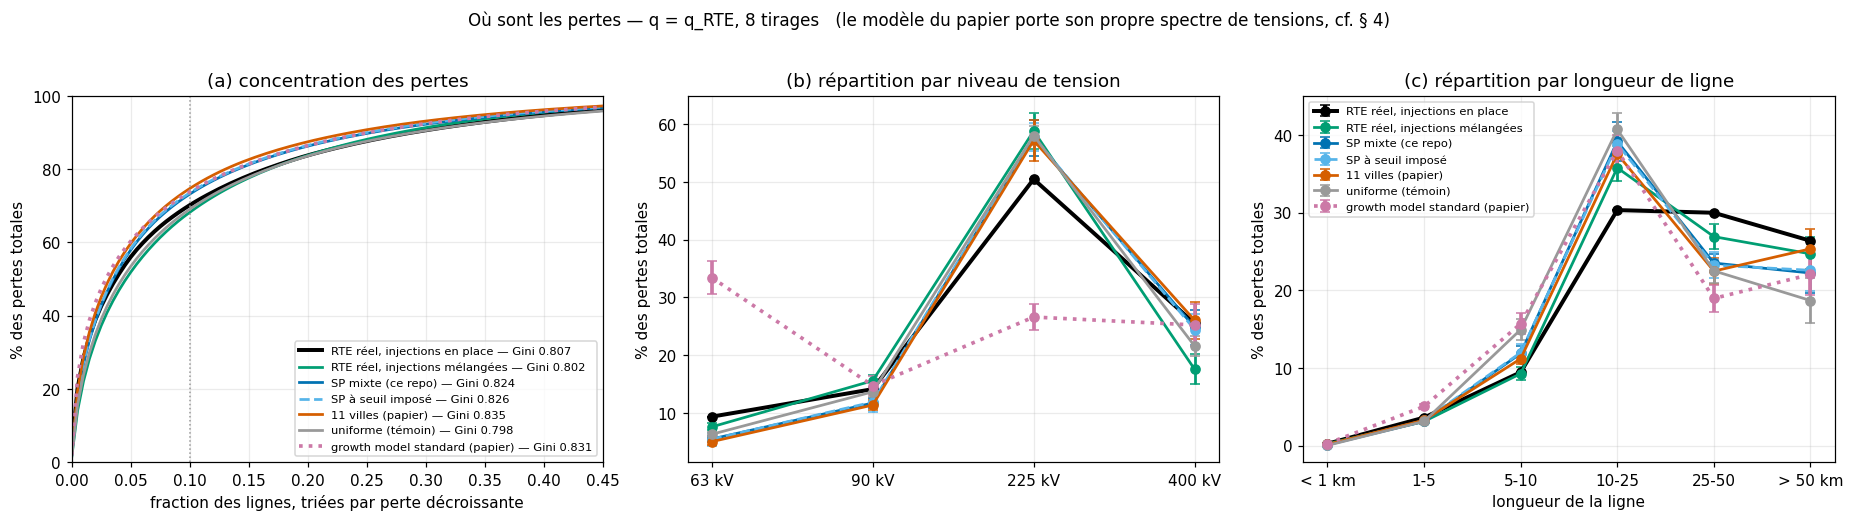

                                   Gini  top 10 %     63 kV     90 kV    225 kV    400 kV   < 1 km      1-5     5-10    10-25    25-50  > 50 km
RTE réel, injections en place     0.807     70.2%       9.3      14.1      50.5      25.5      0.3      3.6      9.5     30.3     30.0     26.4
RTE réel, injections mélangées    0.802     68.2%       7.6      15.6      58.8      17.6      0.2      3.1      9.3     35.8     26.9     24.7
SP mixte (ce repo)                0.824     73.2%       5.5      11.7      57.6      24.8      0.1      3.1     11.9     39.2     23.5     22.2
SP à seuil imposé                 0.826     73.5%       5.4      11.9      57.8      24.4      0.1      3.2     12.0     38.8     23.2     22.6
11 villes (papier)                0.835     74.7%       5.0      11.4      57.2      26.0      0.2      3.3     11.2     37.6     22.5     25.3
uniforme (témoin)                 0.798     69.1%       6.3      13.7      58.0      21.6      0.0      3.1     14.9     40.7     22.5  

In [15]:
_cache_lp = CACHE / f"loss_profile_N{N_RTE}_R{N_RUNS}_v3.joblib"
LEV = np.unique(ref["volt_mix"])                      # les 7 niveaux réels, 20 … 400 kV
LBINS = np.array([0, 1e3, 5e3, 1e4, 2.5e4, 5e4, np.inf])
LLAB = ["< 1 km", "1-5", "5-10", "10-25", "25-50", "> 50 km"]
XG = np.linspace(0, 1, 201)                           # grille commune pour Lorenz


def _snap(U):
    """Ramène les tensions du modèle (interpolées par quantiles) sur les 7 niveaux réels."""
    return LEV[np.abs(np.log(U[:, None] / LEV[None, :])).argmin(1)]


def _profile(d):
    """Répartition des pertes d'un réseau : Lorenz, par tension, par longueur."""
    J, U, L = d["J"], _snap(d["U"]), d["L"]
    tot = J.sum()
    lor = np.interp(XG, np.arange(1, len(J) + 1) / len(J),
                    np.cumsum(np.sort(J)[::-1]) / tot)
    x = np.sort(J); n = len(J)
    return dict(lor=lor,
                volt=np.array([J[U == v].sum() for v in LEV]) / tot,
                leng=np.array([J[(L >= LBINS[i]) & (L < LBINS[i + 1])].sum()
                               for i in range(len(LLAB))]) / tot,
                gini=float((2 * np.arange(1, n + 1) - n - 1) @ x / (n * x.sum())),
                top10=float(np.interp(0.10, XG, lor)))


if _cache_lp.exists():
    LP = joblib.load(_cache_lp)
    print("profils de pertes : chargés du cache")
else:
    t0 = time.time()
    LP = {m: [_profile(pg.dc_losses(NETS[m][qk][s], model_P(m, s, "shuffle"),
                                    ref["volt_mix"])) for s in range(N_RUNS)]
          for m in MODELS}
    # le modèle du papier : ses pertes par arête, calculées par son propre code,
    # donc avec SON spectre de tensions et SA file d'attribution
    LP["GM"] = [_profile(PAPER[(qk, s)]) for s in range(N_RUNS)]
    LP["RTEmix"] = [_profile(pg.dc_losses(G_rte, pg.injections_shuffled(ref["P"], s),
                                          ref["volt_mix"])) for s in range(N_RUNS)]
    LP["RTE"] = [_profile(pg.dc_losses(G_rte, ref["P"], ref["volt_mix"]))]
    # deux contrôles pour séparer ce qui vient de la règle et ce qui vient du reste :
    #  - la règle « rangée » sur le vrai réseau, dont l'indice de nœud est arbitraire
    LP["RTEord"] = [_profile(pg.dc_losses(G_rte, P_ORDERED, ref["volt_mix"]))]
    #  - la topologie du papier avec ses injections rangées, mais l'estimateur du
    #    notebook (spectre réel des 6 272 lignes, tensions par rang de flux)
    LP["ORIord"] = [_profile(pg.dc_losses(NETS["ORI"][qk][s], P_ORDERED,
                                          ref["volt_mix"])) for s in range(N_RUNS)]
    joblib.dump(LP, _cache_lp)
    print(f"profils de pertes : {time.time()-t0:.0f} s")


def agg(k, f):
    v = np.array([d[f] for d in LP[k]])
    return v.mean(0), v.std(0)


SERIES = [("RTE", "RTE réel, injections en place", C["rte"], "-", 2.6),
          ("RTEmix", "RTE réel, injections mélangées", C["ref"], "-", 1.8),
          ("SP", LBL["SP"], C["SP"], "-", 1.8),
          ("SP20", LBL["SP20"], C["SP20"], "--", 1.8),
          ("ORI", LBL["ORI"], C["ORI"], "-", 1.8),
          ("RAND", LBL["RAND"], C["RAND"], "-", 1.8),
          ("GM", "growth model standard (papier)", C["warn"], ":", 2.4)]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

ax = axes[0]
for k, lab, col, ls, lw in SERIES:
    mu, _ = agg(k, "lor")
    g = np.mean([d["gini"] for d in LP[k]])
    ax.plot(XG, 100 * mu, ls, color=col, lw=lw, label=f"{lab} — Gini {g:.3f}")
ax.axvline(0.10, color="0.6", lw=1, ls=":")
ax.set_xlim(0, 0.45); ax.set_ylim(0, 100)
ax.set_xlabel("fraction des lignes, triées par perte décroissante")
ax.set_ylabel("% des pertes totales")
ax.set_title("(a) concentration des pertes"); ax.legend(fontsize=7.5, loc="lower right")
ax.grid(alpha=.25)

ax = axes[1]
keep = [i for i, v in enumerate(LEV) if np.mean([d["volt"][i] for d in LP["RTE"]]) > 0.01]
xs = np.arange(len(keep))
for k, lab, col, ls, lw in SERIES:
    mu, sd = agg(k, "volt")
    ax.errorbar(xs, 100 * mu[keep], yerr=100 * sd[keep], fmt="o" + ls, color=col, lw=lw,
                ms=6, capsize=3, label=lab)
ax.set_xticks(xs); ax.set_xticklabels([f"{LEV[i]/1e3:.0f} kV" for i in keep])
ax.set_ylabel("% des pertes totales")
ax.set_title("(b) répartition par niveau de tension"); ax.grid(alpha=.25)

ax = axes[2]
xs = np.arange(len(LLAB))
for k, lab, col, ls, lw in SERIES:
    mu, sd = agg(k, "leng")
    ax.errorbar(xs, 100 * mu, yerr=100 * sd, fmt="o" + ls, color=col, lw=lw, ms=6,
                capsize=3, label=lab)
ax.set_xticks(xs); ax.set_xticklabels(LLAB)
ax.set_xlabel("longueur de la ligne"); ax.set_ylabel("% des pertes totales")
ax.set_title("(c) répartition par longueur de ligne")
ax.legend(fontsize=7.5, loc="upper left"); ax.grid(alpha=.25)

fig.suptitle("Où sont les pertes — q = q_RTE, "
             f"{N_RUNS} tirages   (le modèle du papier porte son propre spectre "
             "de tensions, cf. § 4)", fontsize=11, y=1.02)
plt.tight_layout()
fig.savefig(ROOT / "out" / "06_ou_sont_les_pertes.pdf", bbox_inches="tight")
plt.show()

TABLE = SERIES + [("ORIord", "11 villes, injections rangées", None, None, None),
                  ("RTEord", "RTE réel, injections rangées", None, None, None)]
print(f"{'':<32s}{'Gini':>7s}{'top 10 %':>10s}" + "".join(
    f"{LEV[i]/1e3:>7.0f} kV" for i in keep) + "".join(f"{l:>9s}" for l in LLAB))
for k, lab, *_ in TABLE:
    mu_v, _ = agg(k, "volt"); mu_l, _ = agg(k, "leng")
    print(f"{lab:<32s}{np.mean([d['gini'] for d in LP[k]]):>7.3f}"
          f"{100*np.mean([d['top10'] for d in LP[k]]):>9.1f}%"
          + "".join(f"{100*mu_v[i]:>10.1f}" for i in keep)
          + "".join(f"{100*x:>9.1f}" for x in mu_l))


**Lecture.**

**(a) La concentration est la même partout — et c'est un non-résultat instructif.** Les sept
courbes de Lorenz se superposent : les 10 % de lignes les plus chargées portent **68 à 75 %**
des pertes, le vrai réseau compris (70,2 %). Gini 0,798 à 0,835 contre **0,807** pour RTE, et
le témoin uniforme (0,798) est le plus proche de tous. Cette concentration extrême n'est pas
une signature de géographie : c'est ce que produit J ∝ P² sur n'importe quel réseau maillé
dès que les injections ont une queue lourde.

**(b) Le niveau de tension, lui, sépare violemment — et il condamne la règle du papier.**
C'est le résultat central de cette section :

| | 63 kV | 90 kV | 225 kV | 400 kV |
|---|---|---|---|---|
| **RTE réel, injections en place** | **9,3** | **14,1** | **50,5** | **25,5** |
| growth model standard (papier), son code | **33,4 ± 2,9** | 14,7 | **26,6 ± 2,2** | 25,2 |
| les quatre modèles, tensions par rang de flux | 5,0-6,3 | 11,4-13,7 | 57,2-58,0 | 21,6-26,0 |
| 11 villes + injections rangées, tensions par flux | 10,2 | 15,9 | 51,1 | 22,4 |

Le modèle du papier met **un tiers de ses pertes sur le 63 kV**, contre 9 % dans les données,
et vide son 225 kV de moitié. C'est de loin le plus mauvais profil du tableau, et la cause
est identifiée : sa file `queue_voltage.pop()` attribue les tensions par **ordre de création
d'arête**, pas selon le flux. Or à flux et longueur égaux une ligne 63 kV perd **175 fois**
plus qu'une 400 kV — r(63)/r(400) × (400/63)² = 4,3 × 40,3. Distribuer les tensions sans
regarder le flux revient à laisser du transit réel sur des lignes 175 fois plus dissipatives,
et la facture atterrit sur le 63 kV. C'est le « piège 2 » du § 2.3, mesuré ici non plus sur le
total mais sur la carte des pertes ; et cela explique pourquoi le total du papier tombe juste
malgré tout (§ 6 : la surcoût de sa règle de tension compense exactement le gain de sa règle
d'injection).

**Et la même topologie, avec un dimensionnement correct, retrouve le profil réel.** La ligne
« 11 villes + injections rangées, tensions par rang de flux » donne **10,2 % / 15,9 % /
51,1 % / 22,4 %** contre **9,3 / 14,1 / 50,5 / 25,5** pour le vrai réseau : les quatre cases
tombent. Aucun autre objet du tableau n'en approche — les quatre modèles à placement neutre
plafonnent à 5-6 % sur le 63 kV, et la règle « rangée » appliquée au **vrai** réseau donne
6,1 % / 62,6 %, c'est-à-dire le profil du placement neutre. C'est donc bien la **combinaison**
growth model + injections rangées + tensions par flux qui reproduit la géographie des pertes
en tension, et le § 6 en donne le mécanisme : ranger les injections pose les grosses
puissances sur les nœuds les plus connectés, qui reçoivent alors les hautes tensions, et
laisse le trafic local sur le 63 kV — comme dans la réalité. **Ce n'est pas la recette du
papier**, c'est celle du papier corrigée de son piège 2.

**(c) Sur les longueurs, tout le monde échoue de la même façon — et il rejoint le § 4.** Les
modèles placent 37,6 à 40,7 % des pertes sur les lignes de 10 à 25 km (38,0 % pour le modèle
du papier), contre 35,8 ± 1,6 % pour le vrai réseau à recette égale et 30,3 % avec ses vraies
injections ; et seulement 19,0 à 23,5 % sur les 25-50 km contre 26,9 et 30,0. Autrement dit
**les modèles perdent leur énergie sur des lignes trop courtes**, et le modèle du papier est
le pire des sept sur cette tranche (19,0 ± 1,7 %). C'est la traduction énergétique du constat
du § 4 : leur distribution de longueurs est trop resserrée, ils manquent à la fois les
liaisons très courtes et les longues. Le témoin uniforme, qui a les arêtes les plus longues en
moyenne, est le plus mauvais sur la tranche 5-10 km (14,9 ± 1,4 % contre 9,5 attendus).

**Ce que cela change pour la question de départ.** L'observable est nettement plus riche que
le total. Elle fait trois choses que le scalaire ne faisait pas : elle **disqualifie une règle
de modélisation** (l'attribution des tensions par ordre de création, § 2.3, qui passait
inaperçue parce que son effet se compensait dans le total) ; elle **exhibe un biais
systématique et reproductible** partagé par tous les modèles (trop de pertes sur des lignes
trop courtes) ; et elle montre qu'une recette bien choisie sur la même topologie **retrouve
le profil en tension du réseau réel**. Mais elle ne **discrimine** toujours pas les géométries
d'amas entre elles : sur les trois découpages, une géométrie sans aucune ville reste aussi
proche des données que les modèles agglomérés. Pour cela, ce notebook n'a que deux
observables : la 2PCF des positions (§ 3) et la loi des degrés (§ 4.1).


## 8. Sensibilités

Quatre choix de modélisation restent ouverts. On mesure ce que chacun déplace, sur le modèle
SP à q = q_RTE, pour savoir quelle confiance accorder au chiffre principal. C'est aussi ici
qu'est reléguée la **chaîne de métadonnées du papier** — population → charge ∝ `pop**κ` —
que la § 6 n'utilise pas : on la traite comme ce qu'elle est, une hypothèse dont on chiffre
le coût.


In [16]:
_cache_s = CACHE / "sensitivity_v3.joblib"

if _cache_s.exists():
    SENS = joblib.load(_cache_s)
else:
    t0 = time.time()
    SENS = {}

    def _P_shuffle(s, model="SP"):
        """La recette par défaut du notebook (§ 6) : vecteur réel, placement neutre."""
        return pg.injections_shuffled(ref["P"], seed=s)

    def _P_conso(s, model="SP", **kw):
        """Marginale de charge réelle brassée — la seule qui expose `prod_where`."""
        _, iu = POS[model][s]
        return pg.injections_marginal_load(ref["P_conso"], prod_pool, Ptot,
                                           seed=s, is_urban=iu, **kw)[0]

    def _P_kappa(s, kappa=0.0, model="SP", **kw):
        """La chaîne du papier : population attribuée, puis charge ∝ pop**kappa."""
        _, iu = POS[model][s]
        pop = pg.assign_population(iu, ld["pop_data"], seed=s)
        return pg.injections(pop, prod_pool, Ptot, seed=s, kappa=kappa,
                             is_urban=iu, **kw)[0]

    def _sweep(key, P_of_s, rule="flow", model="SP"):
        v = [pg.loss_pct(NETS[model][qk][s], P_of_s(s), Ptot, ref["volt_mix"],
                         voltage_rule=rule) for s in range(N_RUNS)]
        SENS[key] = (float(np.mean(v)), float(np.std(v)))

    for rule in ("flow", "time", "length", "random"):
        _sweep(("tension", rule), _P_shuffle, rule=rule)
    for pw in ("random", "rural", "urban"):
        _sweep(("production", pw), lambda s, pw=pw: _P_conso(s, prod_where=pw))

    # ce que coûterait de modéliser la charge au lieu de prendre le vecteur publié
    _sweep(("recette", "P mélangé"), _P_shuffle)
    _sweep(("recette", "P rangé"), lambda s: P_ORDERED)
    _sweep(("recette", "conso brassée"), _P_conso)
    for kappa in (0.0, 0.25, 0.5, 1.0):
        _sweep(("recette", f"κ = {kappa}"), lambda s, k=kappa: _P_kappa(s, kappa=k))

    # κ = 1 est le seul régime où la géographie redevient visible : on y remet
    # les autres modèles et la référence, sinon la comparaison n'a pas de juge
    for m in ("SP20", "ORI", "RAND"):
        _sweep(("κ = 1 : les autres modèles", m),
               lambda s, m=m: _P_kappa(s, kappa=1.0, model=m), model=m)
    v = [pg.loss_pct(G_rte, pg.injections(pop_rte, prod_pool, Ptot, seed=s,
                                          kappa=1.0)[0], Ptot, ref["volt_mix"])
         for s in range(N_RUNS)]
    SENS[("κ = 1 : les autres modèles", "RTE réelle")] = (float(np.mean(v)),
                                                          float(np.std(v)))

    # ce que coûte l'aplatissement de κ = 0, mesuré sans modèle : vraie topologie,
    # vraie production en place, seule la consommation est remplacée
    for lab, P in [("conso réelle en place", ref["P"]),
                   ("aplatie à sa moyenne", ref["P_prod"] - ref["P_conso"].mean())]:
        SENS[("aplatissement de κ = 0", lab)] = (
            float(pg.loss_pct(G_rte, P, Ptot, ref["volt_mix"])), 0.0)

    # les deux ordres du papier, découplés puis re-couplés
    _sweep(("ordre", "neutre + flux"), _P_shuffle, rule="flow")
    _sweep(("ordre", "neutre + file"), _P_shuffle, rule="time")
    _sweep(("ordre", "rangée + flux"), lambda s: P_ORDERED, rule="flow")
    _sweep(("ordre", "rangée + file"), lambda s: P_ORDERED, rule="time")
    joblib.dump(SENS, _cache_s)
    print(f"(sensibilités calculées en {time.time()-t0:.0f} s)")

NOTE = {("tension", "flow"): "défaut — dimensionnement par le flux",
        ("tension", "time"): "la file triée du papier (ordre de création)",
        ("tension", "length"): "la plus longue = la plus haute tension",
        ("tension", "random"): "spectre respecté, corrélation détruite",
        ("production", "random"): "défaut — centrales n'importe où",
        ("production", "rural"): "centrales dans le fond aléatoire",
        ("production", "urban"): "centrales dans les amas SP",
        ("recette", "P mélangé"): "défaut § 6 — vecteur publié, placement neutre",
        ("recette", "P rangé"): "§ 6 — vecteur publié, attribution du papier",
        ("recette", "conso brassée"): "marginale de charge réelle, prod. au hasard",
        ("recette", "κ = 0.0"): "chaîne du papier, charge plate",
        ("recette", "κ = 0.25"): "",
        ("recette", "κ = 0.5"): "",
        ("recette", "κ = 1.0"): "charge ∝ métadonnée de population",
        ("κ = 1 : les autres modèles", "SP20"): "SP à seuil imposé",
        ("κ = 1 : les autres modèles", "ORI"): "11 villes (papier)",
        ("κ = 1 : les autres modèles", "RAND"): "témoin uniforme — sans ville",
        ("κ = 1 : les autres modèles", "RTE réelle"): "← le juge",
        ("aplatissement de κ = 0", "conso réelle en place"): "94 paliers départementaux",
        ("aplatissement de κ = 0", "aplatie à sa moyenne"): "ce que fait κ = 0",
        ("ordre", "neutre + flux"): "défaut",
        ("ordre", "neutre + file"): "file du papier, injections non rangées",
        ("ordre", "rangée + flux"): "injections rangées comme le papier",
        ("ordre", "rangée + file"): "les deux ordres du papier, verrouillés"}

TITRE = {"tension": "TENSION", "production": "PRODUCTION", "recette": "RECETTE D'INJECTION",
         "κ = 1 : les autres modèles": "À κ = 1 : LES AUTRES MODÈLES",
         "aplatissement de κ = 0": "CE QUE COÛTE L'APLATISSEMENT DE κ = 0",
         "ordre": "ORDRE DES INJECTIONS × RÈGLE DE TENSION"}
cur = None
for (fam, var), (mu, sd) in SENS.items():
    if fam != cur:
        print(f"  {TITRE[fam]}"); cur = fam
    val = f"{mu:>7.2f} ± {sd:<6.2f}" if sd else f"{mu:>7.2f}        "
    print(f"    {var:<21s} {val}  {NOTE[(fam, var)]}")
print(f"\n  pour mémoire, topologie RTE réelle, recette par défaut (P mélangé) : "
      f"{REF_L['shuffle'][0]:.2f} ± {REF_L['shuffle'][1]:.2f} %")


  TENSION
    flow                     4.04 ± 0.63    défaut — dimensionnement par le flux
    time                    39.07 ± 6.36    la file triée du papier (ordre de création)
    length                  32.56 ± 4.42    la plus longue = la plus haute tension
    random                 130.73 ± 18.47   spectre respecté, corrélation détruite
  PRODUCTION
    random                   4.72 ± 1.21    défaut — centrales n'importe où
    rural                    6.11 ± 1.61    centrales dans le fond aléatoire
    urban                    4.69 ± 0.87    centrales dans les amas SP
  RECETTE D'INJECTION
    P mélangé                4.04 ± 0.63    défaut § 6 — vecteur publié, placement neutre
    P rangé                  3.44 ± 0.61    § 6 — vecteur publié, attribution du papier
    conso brassée            4.72 ± 1.21    marginale de charge réelle, prod. au hasard
    κ = 0.0                  4.57 ± 1.21    chaîne du papier, charge plate
    κ = 0.25                 4.78 ± 1.20    
    κ = 0.

**Lecture.**

*Les tensions dominent tout.* Entre « par rang de flux » et « au hasard », le résultat varie
d'un facteur 32 (4,0 % contre 131 %). Ce choix n'est pas un détail d'implémentation : c'est
le paramètre le plus sensible du modèle, et il doit être documenté comme tel.

*Le bloc « ordre » montre que les deux règles du papier se tiennent l'une l'autre.* Avec des
injections neutres, la file triée des tensions donne 39 % contre 4,0 % pour la règle par flux
— un facteur 10. Mais si on range aussi les injections comme le papier, la file triée retombe
à 6,3 % contre 3,4 %, un facteur 1,8. **La règle des tensions n'est acceptable que parce
qu'elle partage son indice avec celle des injections.** Ce n'est pas une propriété du modèle,
c'est une propriété de l'ordre dans lequel deux files sont dépilées ; elle disparaît dès
qu'on change l'une des deux, et elle n'a aucun équivalent sur un réseau réel — d'où les 84 %
obtenus au § 2.3 en attribuant au hasard le vrai spectre RTE aux vraies lignes, et les 6,3 %
obtenus au § 6 en rangeant les injections sur le vrai réseau.

*Le placement des centrales* déplace le résultat de +29 % : mettre la production dans le fond
rural (ce qui est le cas des centrales nucléaires françaises, en bord de fleuve) allonge les
transits. C'est la sensibilité la plus « physique » du lot, et elle mériterait une
calibration sur les positions réelles des sites du registre national.

*Modéliser la charge coûte cher et n'apporte rien.* Le bloc « recette » compare le vecteur
publié (4,0 % mélangé, 3,4 % rangé) à ce qu'on obtient en le reconstruisant. Reprendre la
seule marginale de consommation réelle donne 4,7 % ; l'aplatir comme κ = 0, 4,6 % — la
consommation ne porte pas 1 % de la variance de P, donc cela ne change rien. Mais κ interpole
ensuite jusqu'à **12,3 %** à κ = 1, en passant par 4,8 et 6,0 : sans seuil, sans plateau,
sans valeur par défaut défendable. **C'est la raison pour laquelle la § 6 n'utilise pas cette
chaîne** — elle ajouterait un paramètre libre valant un facteur 3 sur le résultat, pour
modéliser une grandeur qui est publiée.

*κ = 1 est le seul régime de tout le notebook où la géographie redevient visible.* Les trois
modèles agglomérés montent à 12,3 / 12,5 / 13,0 % quand le témoin uniforme reste à 6,0 %, un
facteur deux : regrouper la charge dans des amas serrés crée des goulots, toute la
consommation d'un amas transitant par les quelques lignes qui le raccordent. La vraie
topologie soumise à la même charge monte à 15,7 %, **au-dessus** des trois modèles agglomérés
(−0,9σ, −0,7σ, −0,6σ) tandis que le témoin uniforme en est à **−3,1σ** — le seul modèle
exclu de tout le notebook. Mais cette exclusion repose entièrement sur κ = 1, c'est-à-dire
sur une proportionnalité charge ↔ densité de population que les données publiées ne
permettent pas de vérifier : on *suppose* alors le couplage au lieu de le mesurer, et c'est
la supposition, non la géométrie, qui discrimine.

*L'aplatissement de κ = 0 se chiffre sans passer par aucun modèle.* Sur la vraie topologie,
production laissée en place, remplacer les 94 paliers départementaux par leur moyenne fait
passer les pertes de **3,20 % à 3,44 %**, soit +0,24 point. C'est le prix exact du raccourci
« charge uniforme » : réel, mais cinq fois moins que le coût de la décorrélation
position ↔ injection mesurée au § 6.


## 9. Conclusion

**La réponse à la question posée : oui, le modèle donne les bonnes valeurs — mais aucune des
raisons de cet accord n'est géographique.**

1. **Le modèle SP mixte donne les bonnes pertes Joule.** À q = q_RTE, avec la règle
   d'injection du papier (injections réelles rangées par indice de nœud) et un dimensionnement
   correct des tensions, il donne **3,44 ± 0,61 %** de la puissance installée
   (**3,06 ± 0,56 %** dans la variante à seuil imposé), contre **3,20 %** pour la vraie
   topologie RTE avec ses vraies injections en place et **3,38 %** publiés par RTE. Remplacer
   la géographie posée à la main par le SP mixte ne casse donc rien de la dynamique
   énergétique du modèle de croissance.

2. **Le modèle du papier, tourné tel quel, retrouve lui aussi le chiffre publié — mais à son
   propre q, et par compensation de deux erreurs.** `grown_graph_pa_flux` donne
   **3,47 ± 0,27 %** à q = 0,5577 contre 3,38 % publiés (+3 %), et **4,66 ± 0,38 %** à
   q_RTE = 0,3558 (+38 %) : l'accord repose sur la convention qui compte les 7 206 ternes
   plutôt que les 6 272 lignes du graphe. Et il repose sur une compensation. Sur la même
   topologie « 11 villes », à q_RTE : injections rangées + tensions par flux → **3,12 %** ;
   injections mélangées + tensions par flux → **4,63 %** ; le papier (rangées + tensions par
   ordre de création) → **4,66 %**. Ranger les injections fait gagner 1,5 point, attribuer les
   tensions par ordre de création en fait reperdre exactement autant. Les deux règles sont
   fausses chacune d'un facteur ~1,5, en sens opposés.

3. **Et l'accord ne vient pas de la géographie.** Deux contrôles, chacun suffisant.
   - Le **témoin uniforme** — zéro ville, aucune structure — donne **3,49 %** sous la même
     règle d'injection : aussi près de la cible que le SP mixte. Une géométrie sans aucune
     agglomération obtient l'accord tout aussi bien.
   - La même règle appliquée au **vrai réseau RTE**, dont l'indice de nœud est arbitraire,
     donne **6,34 %** : deux fois trop, et pire que le placement au hasard (4,41 %).

   La règle n'a donc aucun contenu physique — elle exploite une propriété du modèle de
   croissance : l'indice **est** l'ordre de création, et l'attachement préférentiel fait des
   premiers nœuds les plus connectés (**corr(indice, degré) = −0,61** ; degré moyen 8,7 pour
   les 100 premiers nœuds, 1,8 au-delà du 2 000ᵉ). `np.sort(P)[::-1]` pose les 5,4 GW du plus
   gros producteur sur un hub. **L'accord du papier avec RTE ne mesure pas sa géographie : il
   mesure sa numérotation de nœuds.**

4. **Avec un placement neutre, les pertes ne voient rien du modèle spatial.** Même vecteur
   d'injections, permuté au hasard : SP 4,04, SP= 4,25, 11 villes 4,63, témoin uniforme
   4,29 %, contre **4,41 ± 0,57 %** pour la vraie topologie sous la même recette — soit
   **−0,4σ, −0,2σ, +0,2σ, −0,2σ**, le témoin sans ville étant le deuxième plus proche. Les
   deux contrastes appariés du § 6 vont plus loin : à géométrie identique, le **nombre**
   d'amas ne compte pas (≤ 0,5σ pour +16 % de nœuds structurés) ; à nombre identique, la
   **forme** des amas ne compte pas non plus (≤ 0,4σ). **Les pertes Joule ne sont pas une
   observable discriminante pour un modèle spatial**, et ce résultat ne repose sur aucune
   métadonnée modélisée : les deux recettes prennent le vecteur publié tel quel et ne font
   varier que sa position.

5. **Ce qui manque aux modèles n'est pas de la géométrie, c'est du couplage — et il se
   chiffre.** Sur la vraie topologie, avec le vrai vecteur d'injections : **3,20 %** en place,
   **4,41 %** permuté. Le couplage position ↔ injection vaut **1,2 point, soit +38 %**. Le
   modèle de croissance en retrouve la valeur, mais par un mécanisme qui n'est pas celui des
   données : chez lui les grosses injections sont sur les nœuds les plus **connectés**, alors
   que dans les données elles sont où elles sont pour des raisons géographiques et
   historiques — d'où les 6,34 % quand on transporte la règle sur le vrai réseau. Bon chiffre,
   mauvaise raison. C'est le fil rouge du repo, retrouvé sur une observable physique : la
   structure spatiale seule est faiblement contrainte par les observables agrégées, et c'est
   le **couplage position ↔ métadonnée** qui porte l'information — encore faut-il le produire,
   et non le simuler par un ordre de numérotation.

6. **La loi des degrés est la seule observable topologique qui discrimine (§ 4.1).** Testée en
   distance de variation totale, rapportée au bruit propre de chaque modèle (TV ≈ 0,016 entre
   deux tirages du même modèle) : les cinq modèles sont à **TV = 0,112-0,126 de RTE, soit 6 à
   8 fois leur bruit** (χ² 575-767 à 9 ddl, p < 10⁻¹¹⁸) — tous rejetés, et de la même façon,
   parce qu'une règle « une arête, plus une seconde avec probabilité q » produit une
   décroissance géométrique en k, là où le réseau réel concentre **25,2 %** de ses postes sur
   le degré 3 et n'en a que 4,8 % au degré 4. Mais les quatre modèles agglomérés sont
   indiscernables entre eux (TV 0,016-0,021, le bruit), tandis que le **témoin uniforme s'en
   détache à 3 fois le bruit** (TV 0,043-0,052) et est aussi le plus loin des données
   (0,126 contre 0,112-0,113). L'agglomération pousse donc P(k) dans la bonne direction, de
   façon mesurable, là où les pertes Joule ne la voyaient pas du tout. Le même test valide au
   passage la ré-implémentation de la règle de croissance : mon `grow_network` et le code du
   papier sont à TV = 0,018 l'un de l'autre, c'est-à-dire au niveau du bruit.

7. **La répartition des pertes disqualifie la règle d'attribution des tensions (§ 7).** Le
   § 7 découpe les pertes ligne par ligne au lieu de les sommer, et c'est là que la
   compensation du point 2 se défait. Le modèle du papier met **33,4 ± 2,9 %** de ses pertes
   sur le 63 kV et **26,6 %** sur le 225 kV, contre **9,3 %** et **50,5 %** dans les données :
   le plus mauvais profil des sept séries. La cause est sa file `queue_voltage.pop()`, qui
   attribue les tensions par ordre de création d'arête, alors qu'à flux et longueur égaux une
   ligne 63 kV perd **175 fois** plus qu'une 400 kV. La même topologie avec les injections
   rangées et les **tensions par rang de flux** donne au contraire **10,2 / 15,9 / 51,1 /
   22,4 %** contre 9,3 / 14,1 / 50,5 / 25,5 — les quatre cases tombent, et rien d'autre dans
   le tableau n'en approche. Deux autres constats : la concentration des pertes est la même
   partout (Gini 0,798-0,835 contre 0,807 pour RTE), c'est une propriété de J ∝ P² et pas de
   la géographie ; et **tous** les modèles perdent leur énergie sur des lignes trop courtes
   (37,6-40,7 % sur les 10-25 km contre 30,3 % ; 19,0-23,5 % sur les 25-50 km contre 30,0 %),
   traduction énergétique du déficit de longueurs vu au § 4. Comme au § 6, aucune des trois
   coupes ne sépare les géométries d'amas entre elles.

8. **Sur la fraction urbaine, la revendication doit être nuancée.** Dire que le SP mixte
   « retire un paramètre libre » en faisant sortir la fraction urbaine de la calibration
   reste vrai *en principe* : la 2PCF contraint bel et bien le seuil, par son amplitude
   (§ 3), là où les pertes n'y sont pas sensibles du tout (§ 6). Mais la valeur que produit
   le code (0,17 ± 0,02) est **biaisée basse** — `build_sp_mixture` interpole ξ_data avec
   `left=0.0`, ce qui compte comme nuls les bins de la 2PCF du fractal situés sous la portée
   des données et sur-dilue le mélange d'un facteur ~1,4 en √ρ. La contrainte honnête est
   f ≈ 0,24, c'est-à-dire **au-dessus** du 0,2 posé par le papier. Le paramètre est bien
   déterminé par les données ; c'est notre estimée qui doit être corrigée avant d'être
   annoncée. La variante `SP=`, qui n'appelle pas ρ, sert de contrôle : elle donne les mêmes
   pertes à 0,5σ près, donc ce biais est sans conséquence pour les points 1 à 7.

9. **Quatre corrections à reporter dans le code du papier.**
   - La susceptance doit valoir **U²/X** et non 1/X : sur un réseau multi-tensions, le
     facteur vaut 3,6 (17 % → 4,7 % sur la vraie topologie). Le code du papier fait cela
     correctement — via le double changement d'échelle par (U_ref/U)² — mais de façon
     implicite, et c'est exactement le piège dans lequel tombe toute réimplémentation
     « propre » (celle de `fake_world/SP_PowerGrid/` par exemple).
   - L'attribution des tensions doit être **explicitement liée au flux**. C'est la correction
     la plus lourde de conséquences, et elle est maintenant démontrée deux fois : sur le total
     (§ 8, 43 % au lieu de 4,7 % dès qu'on découple les deux files ; 84 % en attribuant au
     hasard le vrai spectre RTE aux vraies lignes) et sur la carte des pertes (§ 7, un tiers
     des pertes sur le 63 kV contre 9 % dans les données). La file triée actuelle ne tient que
     parce qu'elle partage son indice avec la file des injections, et son erreur ne se voit
     pas dans le total parce qu'elle compense celle de la règle d'injection.
   - **Le q auquel le modèle est comparé doit être explicité.** L'accord de la fig. 6 est
     obtenu à q = 0,5577, qui compte les 7 206 ternes ; à q = 0,3558, la redondance du graphe
     effectivement publié, le même modèle est 38 % au-dessus du chiffre de RTE. La convention
     est défendable — le modèle crée une arête par circuit — mais elle vaut à elle seule tout
     l'écart, et le lecteur doit pouvoir la voir.
   - **κ = 0 n'est pas « la convention des données ».** Le raccourci « charge uniforme »
     confond « réparti à parts égales à l'intérieur de chaque département » avec « constant
     partout » : le vecteur publié est un escalier à 94 marches, de 8,9 à 119,1 MW par
     poste, plus 766 postes à zéro (CV = 0,72), pas une constante. Sur la vraie topologie,
     à production en place, l'aplatissement coûte +0,24 point (3,20 → 3,44 %). L'erreur est
     sans conséquence sur les conclusions 1 à 8 — la § 6 n'utilise pas κ du tout — mais
     l'étiquette doit être corrigée, et le niveau absolu annoncé l'est de 0,25 point trop
     haut.

**Suites naturelles.** (i) Les points 6 et 7 désignent les deux observables qui *ont* mordu :
la loi des degrés, qui sépare « avec amas » de « sans amas » mais pas les géométries d'amas
entre elles, et la répartition des pertes par tension, qui disqualifie une règle de
modélisation. Continuer dans cette direction : centralité d'intermédiarité, ou distribution
des flux rapportée à la distance à l'amas le plus proche, où la structure d'amas doit laisser
une signature que la longueur totale efface. (ii) Les points 3 et 5 désignent la vraie cible :
un modèle qui *produit* le couplage position ↔ injection par un mécanisme géographique, et
qu'on jugerait sur sa capacité à retrouver les 3,2 % **sans** passer par l'ordre de création
des nœuds — le test étant que la règle survive au transport sur le vrai réseau, ce que celle
du papier ne fait pas (6,3 %). La sensibilité au placement des centrales du § 8 (+29 % entre
rural et aléatoire) est le premier levier à calibrer, sur les positions réelles des sites du
registre national. (iii) Rejouer le protocole sur ENEDIS (distribution, N ≈ 900 000), où la
fraction urbaine calibrée est très différente et où le maillage est bien plus faible.


In [17]:
rows = []
for m in MODELS:
    for rc in RECIPES:
        for q in Q_SWEEP:
            k = round(float(q), 4)
            mu, sd = JOULE[(rc, m, k)]
            Gs = NETS[m][k]
            rows.append(dict(
                model=m, label=LBL[m], recipe=rc, recipe_label=RSHORT[rc],
                q_target=k, q_measured=float(np.mean([pg.q_of(G) for G in Gs])),
                N=N_RTE, n_runs=N_RUNS,
                urban_frac=float(np.mean([iu.mean() for _, iu in POS[m]])),
                n_urban=float(np.mean([iu.sum() for _, iu in POS[m]])),
                L_tot_km=float(np.mean([pg.total_length_km(G) for G in Gs])),
                joule_pct=mu, joule_pct_std=sd))
for q in Q_SWEEP:                     # le modèle du papier, tourné tel quel
    k = round(float(q), 4)
    rows.append(dict(
        model="GM", label="growth model standard (papier)", recipe="paper",
        recipe_label="son code, ses deux files", q_target=k, q_measured=k,
        N=N_RTE, n_runs=N_RUNS, urban_frac=np.nan, n_urban=np.nan,
        L_tot_km=float(np.mean([PAPER[(k, s_)]["L"].sum() / 1e3
                                for s_ in range(N_RUNS)])),
        joule_pct=J_GM[k][0], joule_pct_std=J_GM[k][1]))
for rc in RECIPES:
    rows.append(dict(model="RTE", label="topologie RTE réelle", recipe=rc,
                     recipe_label=RSHORT[rc], q_target=np.nan, q_measured=q_RTE,
                     N=N_RTE, n_runs=N_RUNS, urban_frac=np.nan, n_urban=np.nan,
                     L_tot_km=pg.total_length_km(G_rte),
                     joule_pct=REF_L[rc][0], joule_pct_std=REF_L[rc][1]))
for lab, val in [("RTE, injections en place, tensions réelles", REF_L["given"]),
                 ("RTE, injections en place, tensions par flux", REF_L["flow"]),
                 ("valeur publiée par RTE", pg.RTE_PUBLISHED_LOSS_PCT)]:
    rows.append(dict(model="RTE", label=lab, recipe="—", recipe_label="—",
                     q_target=np.nan, q_measured=q_RTE, N=N_RTE, n_runs=1,
                     urban_frac=np.nan, n_urban=np.nan,
                     L_tot_km=pg.total_length_km(G_rte),
                     joule_pct=val, joule_pct_std=0.0))

df_out = pd.DataFrame(rows)
df_out.to_csv(ROOT / "out" / "06_powergrid_sp_joule.csv", index=False)

df_sens = pd.DataFrame([dict(family=f, variant=v, joule_pct=mu, joule_pct_std=sd,
                             note=NOTE[(f, v)])
                        for (f, v), (mu, sd) in SENS.items()])
df_sens.to_csv(ROOT / "out" / "06_powergrid_sp_sensitivity.csv", index=False)

df_deg = pd.DataFrame([dict(model=m, label=DLBL[m], tv_to_rte=TVR[m][0],
                            tv_to_rte_std=TVR[m][1], tv_intra=intra[m][0],
                            ratio=TVR[m][0] / intra[m][0],
                            **{f"pk_{l}": v for l, v in zip(KLAB, PK[m].mean(0))})
                       for m in DKEYS]
                      + [dict(model="RTE", label="RTE réel", tv_to_rte=0.0,
                              tv_to_rte_std=0.0, tv_intra=np.nan, ratio=np.nan,
                              **{f"pk_{l}": v for l, v in zip(KLAB, PK["RTE"][0])})])
df_deg.to_csv(ROOT / "out" / "06_degres.csv", index=False)

print("écrit :")
print("  out/06_powergrid_sp_joule.csv       ", df_out.shape)
print("  out/06_powergrid_sp_sensitivity.csv ", df_sens.shape)
print("  out/06_degres.csv                   ", df_deg.shape)
for f in ("06_nuages", "06_2pcf", "06_topologie", "06_degres", "06_joule_vs_q",
          "06_ou_sont_les_pertes"):
    print(f"  out/{f}.pdf")
df_out[(df_out.q_target == qk)][["label", "recipe_label", "n_urban", "L_tot_km",
                                 "joule_pct", "joule_pct_std"]]

écrit :
  out/06_powergrid_sp_joule.csv        (77, 13)
  out/06_powergrid_sp_sensitivity.csv  (24, 5)
  out/06_degres.csv                    (6, 15)
  out/06_nuages.pdf
  out/06_2pcf.pdf
  out/06_topologie.pdf
  out/06_degres.pdf
  out/06_joule_vs_q.pdf
  out/06_ou_sont_les_pertes.pdf


,label,recipe_label,n_urban,L_tot_km,joule_pct,joule_pct_std
3,SP mixte (ce repo),P rangé/indice,796.125,75376.141486,3.439643,0.608554
11,SP mixte (ce repo),P mélangé,796.125,75376.141486,4.041021,0.626483
19,SP à seuil imposé,P rangé/indice,923.375,74612.425004,3.056720,0.564120
27,SP à seuil imposé,P mélangé,923.375,74612.425004,4.246595,0.674467
35,11 villes (papier),P rangé/indice,923.375,73458.874347,3.118114,0.385997
43,11 villes (papier),P mélangé,923.375,73458.874347,4.629212,0.786016
51,uniforme (témoin),P rangé/indice,0.000,78124.333902,3.487694,0.511366
59,uniforme (témoin),P mélangé,0.000,78124.333902,4.287887,0.475229
67,growth model standard (papier),"son code, ses deux files",NaN,73081.418229,4.658203,0.378233
